# Reconnaissance d’expressions faciales — Projet Deep Learning

**Fondamentaux du Deep Learning**

Binôme : Paul Douat et Sami Nakib

L’objectif de ce projet est simple à énoncer : apprendre à un réseau de neurones à reconnaître sept expressions du visage (colère, dégoût, peur, joie, neutre, tristesse et surprise). On travaille sur les visages déjà recadrés de FER-2013. On commence par comparer un réseau dense classique à un CNN, puis on teste plusieurs architectures et on essaie le transfer learning avec MobileNetV2. Pour finir, on branche notre meilleur CNN derrière un détecteur de visages afin de l’utiliser sur de vraies photos et sur des vidéos.

Tous les chiffres commentés dans ce notebook viennent des sorties de nos propres exécutions.

## Sommaire

1. **Partie 1** : Découverte et préparation des données FER-2013
2. **Partie 2** : Un premier modèle de référence, le réseau dense
3. **Partie 3** : Construction d’un CNN avec Keras
4. **Partie 4** : Entraînement du CNN
5. **Partie 5** : Évaluation et analyse des erreurs
6. **Partie 6** : Recherche aléatoire et expériences ciblées
7. **Partie 7** : Transfer learning avec MobileNetV2
8. **Partie 8** : Détecter et classer plusieurs visages
9. **Partie 9** : Passage à la vidéo

## Comment on s’y est pris

On part d’un réseau dense pour avoir un point de comparaison, puis on entraîne un premier CNN. Ensuite, on explore 24 configurations au hasard, avant de creuser trois pistes plus précises : la profondeur, le nombre de filtres et la régularisation. Le modèle final reprend la meilleure configuration trouvée, à laquelle on ajoute la Batch Normalization et l’augmentation de données.

Un point de méthode : c’est la validation qui nous sert à départager les configurations. Le jeu de test, lui, est utilisé dès la partie 5 pour le CNN v1, puis pour le modèle final et MobileNetV2. On ne le garde donc pas pour une seule évaluation tout à la fin, et on en tient compte dans nos conclusions.

In [1]:
# Installation des bibliothèques qui ne sont pas fournies par défaut sur Colab :
# kagglehub pour télécharger le dataset, ultralytics pour tenter la détection avec YOLO
!pip install -q kagglehub ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 10.2 MB/s eta 0:00:00


In [2]:
# Imports et graines aléatoires (pour pouvoir reproduire nos résultats)
import os, glob, random, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Constantes utilisées dans tout le notebook
TAILLE_IMAGE = 48
CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
NOMS_FR = {"angry": "colère", "disgust": "dégoût", "fear": "peur", "happy": "joie",
           "neutral": "neutre", "sad": "tristesse", "surprise": "surprise"}
NB_CLASSES = len(CLASSES)
TAILLE_BATCH = 64
CHEMIN_RECHERCHE = "/content/resultats_recherche.csv"
CHEMIN_MODELE_FINAL = "/content/modele_final.keras"

print("Version de TensorFlow :", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print("GPU détecté :", gpus[0])
else:
    print("Pas de GPU détecté. Sur Colab : Exécution > Modifier le type d'exécution > GPU.")

Version de TensorFlow : 2.21.0
Super, on a un GPU : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [3]:
def plot_historique(historique, titre="Modèle"):
    """Trace la perte et l'accuracy (entraînement et validation) au fil des époques."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

    # Perte
    ax1.plot(historique.history["loss"], label="Entraînement", color="royalblue", lw=2)
    ax1.plot(historique.history["val_loss"], label="Validation", color="orange", lw=2)
    ax1.set_title(f"{titre} - Perte", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Époques")
    ax1.set_ylabel("Perte")
    ax1.legend()
    ax1.grid(True, linestyle="--", alpha=0.6)

    # Accuracy
    ax2.plot(historique.history["accuracy"], label="Entraînement", color="royalblue", lw=2)
    ax2.plot(historique.history["val_accuracy"], label="Validation", color="orange", lw=2)
    ax2.set_title(f"{titre} - Accuracy", fontsize=12, fontweight="bold")
    ax2.set_xlabel("Époques")
    ax2.set_ylabel("Accuracy")
    ax2.legend()
    ax2.grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()

## Partie 1 : Découverte et préparation des données

On utilise FER-2013, téléchargé depuis Kaggle sous forme de dossiers (un dossier par expression). Au total, on récupère **35 887 images** en niveaux de gris de 48×48 pixels. Les classes sont loin d’être équilibrées : dans le dossier d’entraînement, la joie représente 25,13 % des images, contre seulement 1,52 % pour le dégoût. C’est pour ça qu’on ne se contentera pas du score global et qu’on regardera aussi les résultats classe par classe.

In [4]:
# Téléchargement de FER-2013 avec kagglehub (dataset public, pas besoin de clé API).
# Si la version en dossiers ne répond pas, on se rabat sur une version CSV du même dataset.
import kagglehub

CHEMIN_DATASET = None   # dossier "train" de la version en images
CHEMIN_CSV = None       # fichier fer2013.csv de la version de secours

try:
    racine = kagglehub.dataset_download("msambare/fer2013")
    dossiers_train = glob.glob(os.path.join(racine, "**", "train"), recursive=True)
    if dossiers_train:
        CHEMIN_DATASET = dossiers_train[0]
        print("Dataset téléchargé (dossiers d'images) :", CHEMIN_DATASET)
except Exception as e:
    print("Impossible de récupérer la version en dossiers :", e)

if CHEMIN_DATASET is None:
    try:
        racine = kagglehub.dataset_download("deadskull7/fer2013")
        fichiers_csv = glob.glob(os.path.join(racine, "**", "*.csv"), recursive=True)
        if fichiers_csv:
            CHEMIN_CSV = fichiers_csv[0]
            print("Dataset téléchargé (fichier CSV) :", CHEMIN_CSV)
    except Exception as e:
        print("La version CSV n'a pas fonctionné non plus :", e)

if CHEMIN_DATASET is None and CHEMIN_CSV is None:
    raise RuntimeError("Dataset introuvable : téléchargez FER-2013 depuis Kaggle "
                       "et indiquez son chemin dans CHEMIN_DATASET.")

Using Colab cache for faster access to the 'fer2013' dataset.
Dataset téléchargé sous forme de dossiers : /kaggle/input/fer2013/train


In [5]:
# Chargement des images en mémoire
def charger_dossier(chemin):
    """Lit les images d'un dossier FER-2013 (train ou test).
    Renvoie X de forme (n, 48, 48) et les étiquettes y sous forme d'entiers."""
    X, y = [], []
    for indice, classe in enumerate(CLASSES):
        fichiers = sorted(glob.glob(os.path.join(chemin, classe, "*.png")))
        if not fichiers:
            fichiers = sorted(glob.glob(os.path.join(chemin, classe, "*.jpg")))
        for f in fichiers:
            img = Image.open(f).convert("L")  # on force les niveaux de gris
            X.append(np.array(img, dtype=np.uint8))
            y.append(indice)
    return np.array(X), np.array(y, dtype=np.int64)


def charger_csv(chemin):
    """Version de secours : lit fer2013.csv (mêmes labels 0-6 que CLASSES).
    Renvoie (X_train, y_train, X_test, y_test), le test étant la partie PublicTest."""
    df = pd.read_csv(chemin)
    X = np.stack([np.array(p.split(), dtype=np.uint8).reshape(48, 48)
                  for p in df["pixels"]])
    y = df["emotion"].to_numpy(dtype=np.int64)
    entrainement = (df["Usage"] == "Training").to_numpy()
    test = (df["Usage"] == "PublicTest").to_numpy()
    return X[entrainement], y[entrainement], X[test], y[test]


if CHEMIN_DATASET is not None:
    print("Chargement des images d'entraînement...")
    X_brut, y_brut = charger_dossier(CHEMIN_DATASET)

    # Le dossier de test se trouve à côté du dossier train
    dossier_parent = os.path.dirname(CHEMIN_DATASET)
    chemin_test = os.path.join(dossier_parent, "test")
    if not os.path.exists(chemin_test):
        chemin_test = os.path.join(dossier_parent, "validation")
    print("Chargement des images de test...")
    X_test_brut, y_test = charger_dossier(chemin_test)
else:
    print("Chargement depuis le CSV...")
    X_brut, y_brut, X_test_brut, y_test = charger_csv(CHEMIN_CSV)

print(f"Images d'entraînement : {X_brut.shape[0]}")
print(f"Images de test : {X_test_brut.shape[0]}")

Chargement des données d'entraînement...
Chargement des données de test...
Données d'entraînement chargées : 28709 images.
Données de test chargées : 7178 images.


### À quoi ressemblent les données ?

On a **28 709 images dans le dossier d’entraînement et 7 178 dans le dossier de test**, soit 35 887 en tout. Le graphique et le tableau ci-dessous montrent bien le déséquilibre : 7 215 images de joie contre à peine 436 de dégoût côté entraînement. La grille d’exemples, elle, donne une idée concrète des visages que le modèle devra classer, et de la difficulté de la tâche.

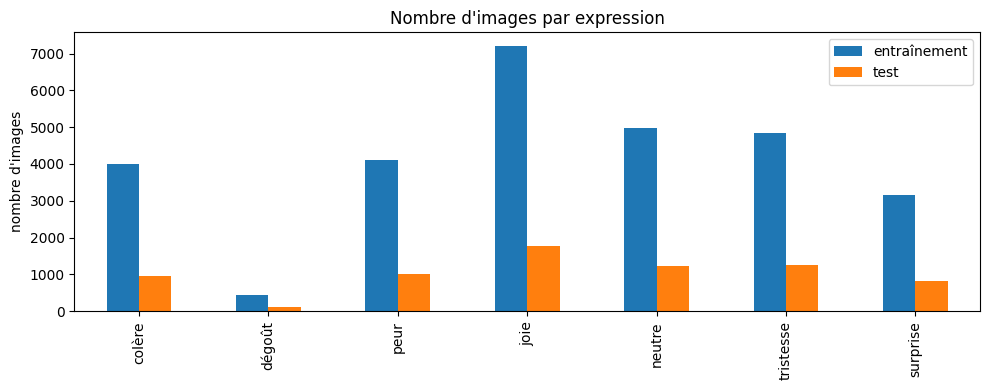

,classe,entraînement,test
0,colère,3995,958
1,dégoût,436,111
2,peur,4097,1024
3,joie,7215,1774
4,neutre,4965,1233
5,tristesse,4830,1247
6,surprise,3171,831


In [6]:
# Nombre d'images par expression, en entraînement et en test
comptages = pd.DataFrame({
    "classe": [NOMS_FR[c] for c in CLASSES],
    "entraînement": [(y_brut == i).sum() for i in range(NB_CLASSES)],
    "test": [(y_test == i).sum() for i in range(NB_CLASSES)],
})
comptages.plot(x="classe", kind="bar", figsize=(10, 4))
plt.title("Nombre d'images par expression")
plt.ylabel("nombre d'images"); plt.xlabel("")
plt.tight_layout(); plt.show()
comptages

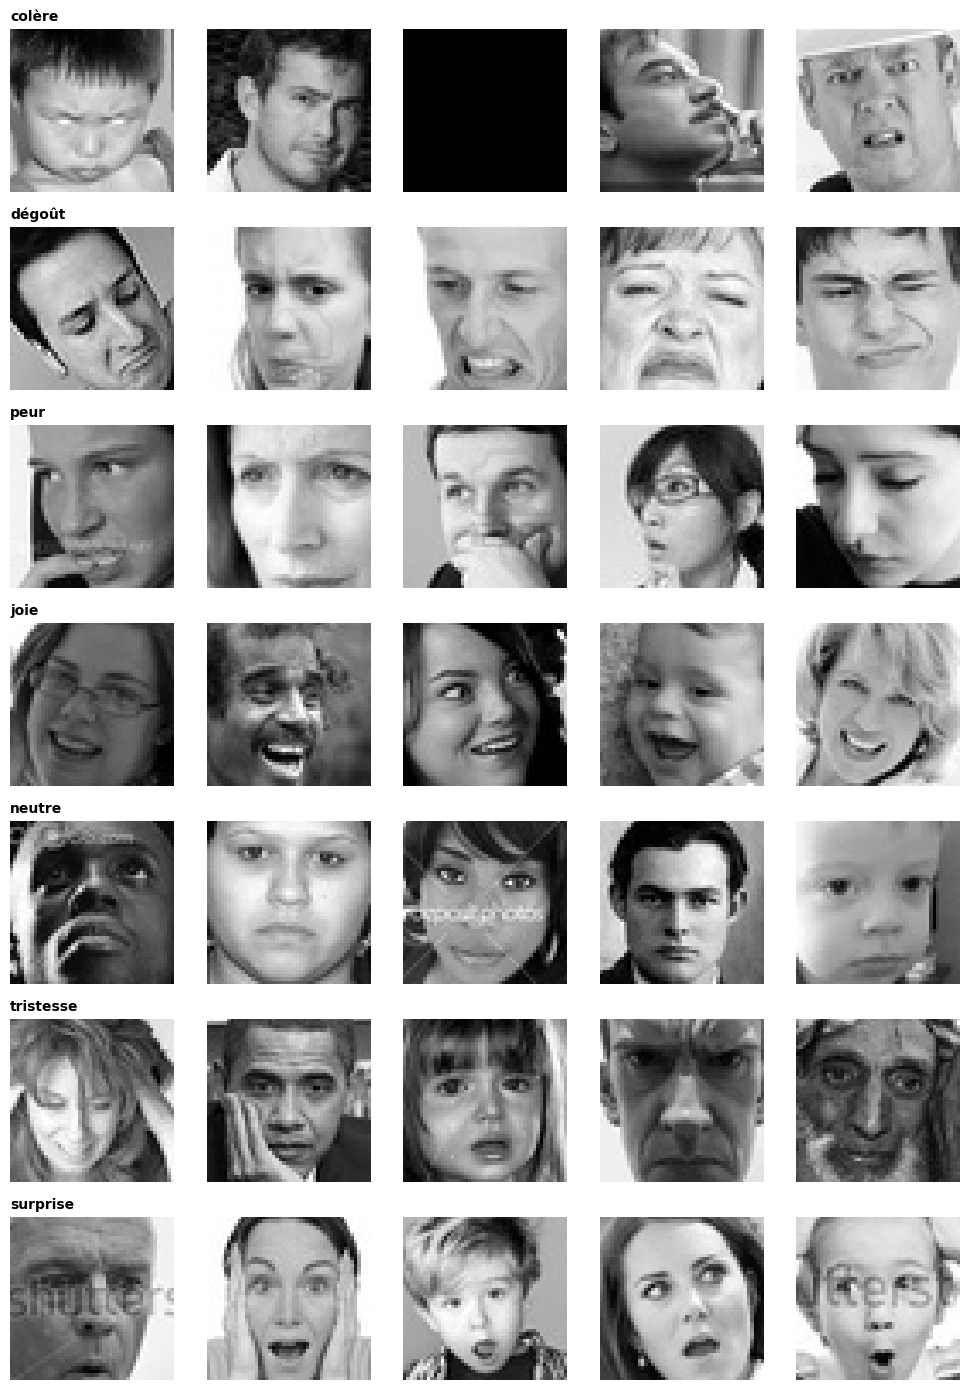

In [7]:
def grille_exemples(X, y, n_par_classe=5):
    """Affiche n_par_classe images pour chacune des 7 expressions."""
    fig, axes = plt.subplots(NB_CLASSES, n_par_classe, figsize=(2 * n_par_classe, 2 * NB_CLASSES))

    for indice_classe in range(NB_CLASSES):
        # On prend simplement les premières images de la classe
        indices = np.where(y == indice_classe)[0][:n_par_classe]

        for j, idx in enumerate(indices):
            ax = axes[indice_classe, j]
            ax.imshow(X[idx], cmap="gray")
            ax.axis("off")
            # Le nom de l'expression seulement sur la première colonne, pour rester lisible
            if j == 0:
                ax.set_title(NOMS_FR[CLASSES[indice_classe]], fontsize=10,
                             loc="left", fontweight="bold")

    plt.tight_layout()
    plt.show()

grille_exemples(X_brut, y_brut, n_par_classe=5)

### Préparation des données

Voici ce qu’on fait aux images avant de les donner au réseau :

- **Format** : les images sont en niveaux de gris, en 48×48. On ajoute juste une dimension de canal pour obtenir des entrées de forme `(48, 48, 1)`, comme Keras l’attend.
- **Normalisation** : les pixels passent en `float32` et sont divisés par 255, pour être ramenés entre 0 et 1.
- **Étiquettes** : chaque expression est codée par un entier de 0 à 6, dans l’ordre de `CLASSES`. La perte `sparse_categorical_crossentropy` accepte ces entiers directement, pas besoin de one-hot.
- **Découpage** : on met de côté 3 589 des 28 709 images d’entraînement pour la validation. Il en reste 25 120 pour apprendre les poids. Les 7 178 images de test restent complètement à part.

Le découpage est stratifié : chaque expression garde la même proportion dans l’entraînement et dans la validation (ça ne rééquilibre pas les classes pour autant). Avec la graine fixée à 42, on retombe toujours sur le même découpage.

In [8]:
# Découpage stratifié train / validation, puis normalisation au format (n, 48, 48, 1)
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_brut, y_brut, test_size=3589, stratify=y_brut, random_state=SEED)

X_train = (X_train.astype("float32") / 255.0)[..., None]
X_val = (X_val.astype("float32") / 255.0)[..., None]
X_test = (X_test_brut.astype("float32") / 255.0)[..., None]

print("X_train :", X_train.shape, " X_val :", X_val.shape, " X_test :", X_test.shape)
print("y_train :", y_train.shape, " y_val :", y_val.shape, " y_test :", y_test.shape)

X_train : (25120, 48, 48, 1)  X_val : (3589, 48, 48, 1)  X_test : (7178, 48, 48, 1)
y_train : (25120,)  y_val : (3589,)  y_test : (7178,)


In [9]:
# On vérifie que la stratification a bien conservé les proportions de chaque expression
proportions = pd.DataFrame({
    "Expression": [NOMS_FR[c] for c in CLASSES],
    "Entraînement (%)": [round((y_train == i).sum() / len(y_train) * 100, 2) for i in range(NB_CLASSES)],
    "Validation (%)": [round((y_val == i).sum() / len(y_val) * 100, 2) for i in range(NB_CLASSES)]
})

display(proportions)

,Expression,Entraînement (%),Validation (%)
0,colère,13.92,13.90
1,dégoût,1.52,1.53
2,peur,14.27,14.27
3,joie,25.13,25.13
4,neutre,17.29,17.30
5,tristesse,16.82,16.83
6,surprise,11.05,11.03


On se retrouve donc avec **25 120 images d’entraînement, 3 589 de validation et 7 178 de test**, toutes au format `(48, 48, 1)`. Le tableau confirme que les proportions sont bien les mêmes des deux côtés.

Avant d’entraîner quoi que ce soit, fixons deux repères. Le réseau sort sept probabilités via une softmax : en répondant au hasard, on aurait environ 14,3 % de bonnes réponses. Mais comme la joie est surreprésentée, un modèle qui répondrait « joie » à chaque fois atteindrait déjà environ 25 %. C’est ce deuxième chiffre qu’il faudra vraiment battre.

## Partie 2 : Un premier modèle de référence, le réseau dense

Pour commencer, on entraîne un réseau dense tout simple, qui nous servira de point de comparaison. Une couche `Flatten` transforme chaque image en un vecteur de 2 304 valeurs, qui passe ensuite dans une couche de 256 neurones (ReLU), un Dropout de 0,3, puis une sortie de sept neurones avec softmax. D’après le résumé, le modèle compte 591 879 paramètres.

### Petit rappel sur le fonctionnement du réseau

Chaque neurone dense fait une somme pondérée de ses entrées, ajoute un biais, puis applique une fonction d’activation. Ici, c’est ReLU : les valeurs négatives deviennent zéro, les positives passent telles quelles.

Pendant la propagation avant, l’image traverse les couches jusqu’à la softmax, qui renvoie sept probabilités dont la somme fait 1. L’entropie croisée pénalise le modèle quand il donne une faible probabilité à la bonne classe. La rétropropagation calcule ensuite le gradient de cette perte par rapport à chaque poids, et Adam s’en sert pour mettre les poids à jour.

In [ ]:
# Modèle de référence : un réseau dense tout simple
keras.utils.set_random_seed(SEED)
baseline = keras.Sequential([
    layers.Input(shape=(48, 48, 1)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NB_CLASSES, activation="softmax"),
], name="baseline_dense")
baseline.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
baseline.summary()

Model: "baseline_dense"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,879 (2.26 MB)

 Trainable params: 591,879 (2.26 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
393/393 - 6s - 16ms/step - accuracy: 0.2478 - loss: 1.8401 - val_accuracy: 0.2661 - val_loss: 1.7990
Epoch 2/20
393/393 - 1s - 3ms/step - accuracy: 0.2793 - loss: 1.7654 - val_accuracy: 0.3087 - val_loss: 1.7597
Epoch 3/20
393/393 - 2s - 4ms/step - accuracy: 0.2915 - loss: 1.7451 - val_accuracy: 0.3087 - val_loss: 1.7348
Epoch 4/20
393/393 - 1s - 3ms/step - accuracy: 0.3005 - loss: 1.7307 - val_accuracy: 0.3210 - val_loss: 1.7256
Epoch 5/20
393/393 - 1s - 3ms/step - accuracy: 0.2977 - loss: 1.7278 - val_accuracy: 0.2965 - val_loss: 1.7378
Epoch 6/20
393/393 - 1s - 3ms/step - accuracy: 0.3031 - loss: 1.7231 - val_accuracy: 0.3065 - val_loss: 1.7300
Epoch 7/20
393/393 - 1s - 3ms/step - accuracy: 0.3035 - loss: 1.7164 - val_accuracy: 0.3232 - val_loss: 1.7074
Epoch 8/20
393/393 - 1s - 3ms/step - accuracy: 0.3037 - loss: 1.7158 - val_accuracy: 0.3279 - val_loss: 1.7103
Epoch 9/20
393/393 - 1s - 3ms/step - accuracy: 0.3096 - loss: 1.7082 - val_accuracy: 0.3249 - val_loss: 1.7083


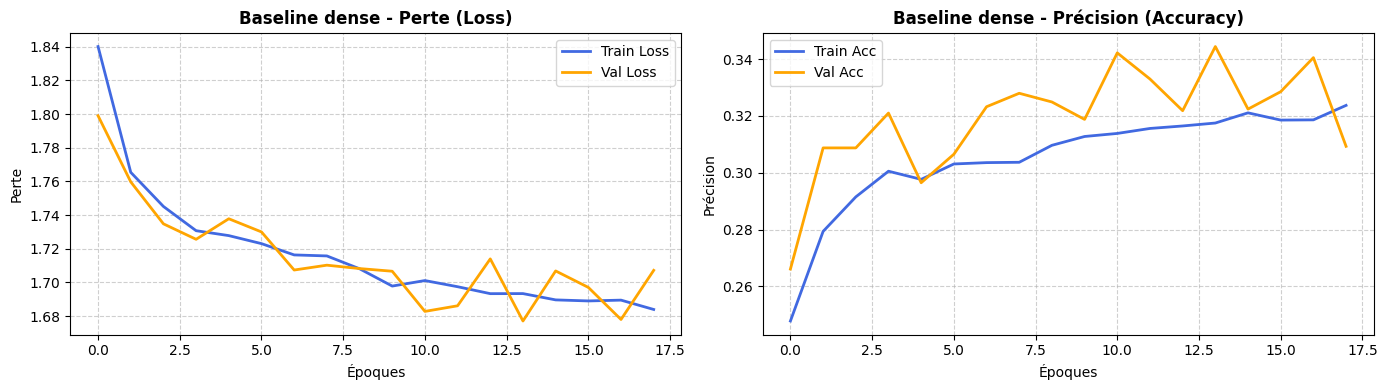

In [ ]:
# Entraînement de la baseline : 20 époques au maximum, avec arrêt anticipé sur la perte de validation
keras.utils.set_random_seed(SEED)
rappels_baseline = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                                  restore_best_weights=True)]
histo_baseline = baseline.fit(X_train, y_train, batch_size=TAILLE_BATCH, epochs=20,
                              validation_data=(X_val, y_val),
                              callbacks=rappels_baseline, verbose=2)
meilleure_val_baseline = max(histo_baseline.history["val_accuracy"])
plot_historique(histo_baseline, "Baseline dense")

Le réseau dense plafonne à **34,44 % d’accuracy en validation**. C’est mieux que nos deux repères (14,3 % et 25 %), mais ça reste faible.

On voit d’ailleurs où sont passés les paramètres : la première couche dense en concentre 590 080 sur 591 879. En aplatissant l’image, le réseau voit les pixels comme une longue liste et ne sait pas lesquels sont voisins. Or, sur un visage, c’est justement l’agencement local des pixels (le coin d’une bouche, un sourcil froncé) qui porte l’information. C’est ce que les convolutions vont nous permettre d’exploiter.

In [ ]:
def tableau_couches(modele):
    """Affiche, couche par couche, la forme de sortie et le nombre de paramètres."""
    print(f"Structure détaillée du modèle : {modele.name}\n")
    print(f"{'Nom de la couche':<25} | {'Type':<18} | {'Dimension de sortie':<22} | {'Paramètres':<10}")
    print("-" * 83)
    for couche in modele.layers:
        try:
            # Keras 3 n'a plus l'attribut output_shape : on passe par le tenseur de sortie
            dimension = str(tuple(couche.output.shape))
        except (AttributeError, ValueError):
            dimension = "inconnue"
        print(f"{couche.name:<25} | {couche.__class__.__name__:<18} | "
              f"{dimension:<22} | {couche.count_params():<10,}")
    print("-" * 83)
    print(f"Total des paramètres : {modele.count_params():,}\n")

# Répartition des paramètres dans le réseau dense
tableau_couches(baseline)

Structure détaillée du modèle : baseline_dense

Nom de la couche          | Type               | Dimension de sortie    | Paramètres
-----------------------------------------------------------------------------------
flatten                   | Flatten            | Multiple/Inconnue      | 0         
dense                     | Dense              | Multiple/Inconnue      | 590,080   
dropout                   | Dropout            | Multiple/Inconnue      | 0         
dense_1                   | Dense              | Multiple/Inconnue      | 1,799     
-----------------------------------------------------------------------------------
Total des paramètres : 591,879



## Partie 3 : Construction d’un CNN avec Keras

Le principe d’une convolution, c’est de faire glisser de petits filtres sur l’image pour produire des cartes de caractéristiques. Les poids de ces filtres sont appris pendant l’entraînement : ils finissent par réagir à des contours, des textures, puis à des combinaisons de motifs utiles pour reconnaître une expression. (On n’a pas visualisé leurs activations dans ce projet, donc on ne peut pas dire précisément ce que chaque filtre détecte.)

Notre CNN v1 utilise des filtres 3×3 avec un padding `same`, ce qui garde la même résolution après chaque convolution. Un MaxPooling 2×2 divise ensuite la hauteur et la largeur par deux. On a écrit une seule fonction paramétrable pour construire tous nos CNN : elle nous resservira pour les expériences de la partie 6.

In [13]:
# Une seule fonction pour construire tous nos CNN : le v1, ceux de la pré-étude (partie 6)
# et le modèle final.
def construire_cnn(nb_blocs=2, filtres=(32, 64), taille_kernel=3, nb_dense=128,
                   activation="relu", dropout=0.4, batchnorm=False, augmentation=False,
                   forme_entree=(48, 48, 1)):
    """CNN paramétrable : nb_blocs blocs [Conv x2 + MaxPool + Dropout],
    puis Flatten + Dense + Dropout + Softmax. Le bloc i utilise filtres[i] ;
    s'il y a plus de blocs que de valeurs de filtres, on reboucle au début
    (filtres[i % len(filtres)])."""
    entree = layers.Input(shape=forme_entree)
    x = entree
    if augmentation:
        # Ces couches ne transforment les images que pendant l'entraînement
        x = layers.RandomFlip("horizontal")(x)
        x = layers.RandomRotation(0.1)(x)
        x = layers.RandomZoom(0.1)(x)
        x = layers.RandomContrast(0.2)(x)
    for i in range(nb_blocs):
        nb_f = filtres[i % len(filtres)]
        for _ in range(2):
            x = layers.Conv2D(nb_f, taille_kernel, padding="same", activation=activation)(x)
            if batchnorm:
                x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Dropout(dropout)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(nb_dense, activation=activation)(x)
    x = layers.Dropout(dropout)(x)
    sortie = layers.Dense(NB_CLASSES, activation="softmax")(x)
    return keras.Model(entree, sortie,
                       name=f"cnn_b{nb_blocs}_k{taille_kernel}_d{nb_dense}")

In [14]:
# CNN v1 : notre point de départ (la partie 6 cherchera à faire mieux)
keras.utils.set_random_seed(SEED)
cnn_v1 = construire_cnn(nb_blocs=2, filtres=(32, 64), taille_kernel=3,
                        nb_dense=128, activation="relu", dropout=0.4)
cnn_v1.compile(optimizer=keras.optimizers.Adam(1e-3),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_v1.summary()

Model: "cnn_b2_k3_d128"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,179,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,245,671 (4.75 MB)

 Trainable params: 1,245,671 (4.75 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# Comment évoluent les dimensions et les paramètres d'une couche à l'autre
tableau_couches(cnn_v1)

Structure détaillée du modèle : cnn_b2_k3_d128

Nom de la couche          | Type               | Dimension de sortie    | Paramètres
-----------------------------------------------------------------------------------
input_layer_1             | InputLayer         | Multiple/Inconnue      | 0         
conv2d                    | Conv2D             | Multiple/Inconnue      | 320       
conv2d_1                  | Conv2D             | Multiple/Inconnue      | 9,248     
max_pooling2d             | MaxPooling2D       | Multiple/Inconnue      | 0         
dropout_1                 | Dropout            | Multiple/Inconnue      | 0         
conv2d_2                  | Conv2D             | Multiple/Inconnue      | 18,496    
conv2d_3                  | Conv2D             | Multiple/Inconnue      | 36,928    
max_pooling2d_1           | MaxPooling2D       | Multiple/Inconnue      | 0         
dropout_2                 | Dropout            | Multiple/Inconnue      | 0         
flatten_1         

### Ce que disent les dimensions

Chaque bloc du CNN v1 enchaîne deux convolutions. Dans le premier, l’entrée 48×48×1 devient 48×48×32, puis le pooling la ramène à 24×24×32. Le deuxième bloc produit des cartes 24×24×64, réduites à 12×12×64 par le second pooling.

Une fois aplati, ça donne 9 216 valeurs. Résultat : la couche dense de 128 neurones pèse à elle seule **1 179 776 paramètres**, contre 64 992 pour les quatre convolutions réunies. Au total, le modèle a 1 245 671 paramètres, soit plus que notre réseau dense. Le partage des poids rend les convolutions très économes, mais c’est la couche dense finale qui fait gonfler le compteur.

### Pourquoi ces choix pour commencer ?

- **Deux blocs** : c’est un point de départ raisonnable pour des images aussi petites que 48×48.
- **32 puis 64 filtres** : on augmente le nombre de cartes à mesure que la résolution diminue, ce qui est l’usage classique.
- **Des kernels 3×3** : ils captent des motifs locaux sans multiplier les poids.
- **Un Dropout de 0,4** : pour freiner le surapprentissage.

Ce sont des choix de départ, pas des certitudes. Les expériences de la partie 6 nous diront s’ils tiennent la route.

## Partie 4 : Entraînement du réseau

On entraîne avec la perte `sparse_categorical_crossentropy`, adaptée à nos étiquettes entières, et l’optimiseur Adam avec un taux d’apprentissage de 0,001. Les images passent par lots de 64, sur 30 époques au maximum.

L’arrêt anticipé surveille la perte de validation : si elle ne s’améliore pas pendant six époques, l’entraînement s’arrête et on récupère les poids de l’époque où elle était la plus basse. Attention, cette époque n’est pas forcément celle où l’accuracy de validation est la meilleure.

In [16]:
# Entraînement du CNN v1
keras.utils.set_random_seed(SEED)
rappels = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=6,
                                         restore_best_weights=True)]
t0 = time.time()
histo_v1 = cnn_v1.fit(X_train, y_train, batch_size=TAILLE_BATCH, epochs=30,
                      validation_data=(X_val, y_val), callbacks=rappels, verbose=2)
print(f"Durée : {time.time() - t0:.0f} s")
meilleure_val_v1 = max(histo_v1.history["val_accuracy"])

Epoch 1/30
393/393 - 26s - 66ms/step - accuracy: 0.2801 - loss: 1.7586 - val_accuracy: 0.3525 - val_loss: 1.6667
Epoch 2/30
393/393 - 5s - 13ms/step - accuracy: 0.3855 - loss: 1.5763 - val_accuracy: 0.4124 - val_loss: 1.4852
Epoch 3/30
393/393 - 5s - 12ms/step - accuracy: 0.4492 - loss: 1.4268 - val_accuracy: 0.4823 - val_loss: 1.3427
Epoch 4/30
393/393 - 5s - 12ms/step - accuracy: 0.4923 - loss: 1.3329 - val_accuracy: 0.5183 - val_loss: 1.2645
Epoch 5/30
393/393 - 5s - 13ms/step - accuracy: 0.5124 - loss: 1.2726 - val_accuracy: 0.5213 - val_loss: 1.2378
Epoch 6/30
393/393 - 5s - 12ms/step - accuracy: 0.5314 - loss: 1.2235 - val_accuracy: 0.5297 - val_loss: 1.2247
Epoch 7/30
393/393 - 5s - 13ms/step - accuracy: 0.5503 - loss: 1.1818 - val_accuracy: 0.5503 - val_loss: 1.2089
Epoch 8/30
393/393 - 5s - 12ms/step - accuracy: 0.5599 - loss: 1.1506 - val_accuracy: 0.5573 - val_loss: 1.1905
Epoch 9/30
393/393 - 5s - 12ms/step - accuracy: 0.5752 - loss: 1.1136 - val_accuracy: 0.5634 - val_loss

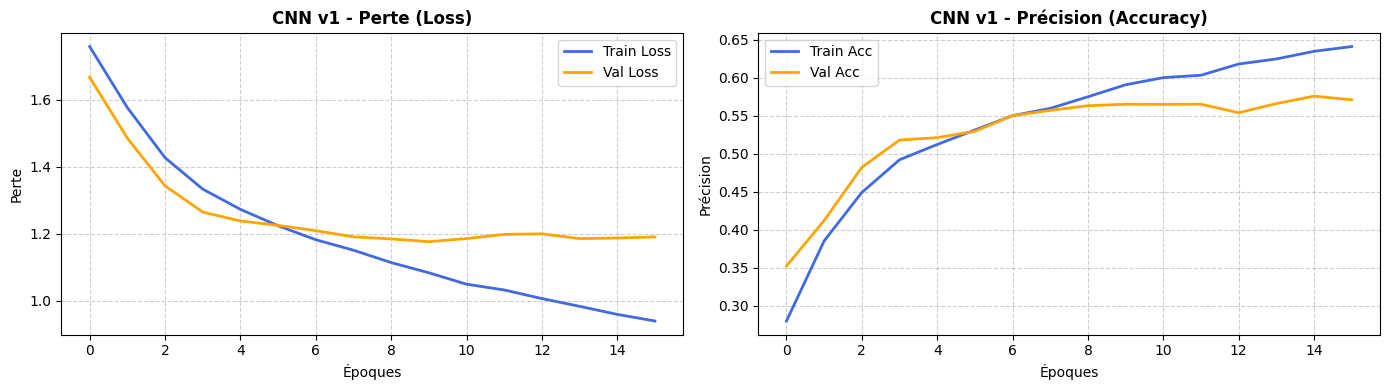

In [17]:
# Courbes de perte et d'accuracy au fil des époques
plot_historique(histo_v1, "CNN v1")

### Lecture des courbes

L’entraînement s’arrête au bout de **16 époques**, en 101 secondes. La perte de validation atteint son minimum à l’époque 10 (1,1760) puis stagne, alors que la perte d’entraînement continue de descendre. Les deux courbes s’écartent : c’est le signe classique d’un début de surapprentissage.

La meilleure accuracy de validation, **57,59 %**, est obtenue à l’époque 15. Mais comme l’arrêt anticipé surveille la perte et non l’accuracy, ce sont les poids de l’époque 10 qui sont restaurés.

## Partie 5 : Évaluation et analyse des erreurs

On passe maintenant le CNN v1 sur les 7 178 images de test. En plus de l’accuracy, on calcule la précision, le rappel et le F1-score de chaque expression, puis on affiche la matrice de confusion et quelques exemples de prédictions. L’idée est de voir ce que le score global cache, en particulier pour les classes rares.

In [18]:
from sklearn.metrics import confusion_matrix, accuracy_score

def rapport_evaluation(modele, X, y, nom_jeu="test"):
    """Prédit la classe de chaque image, affiche l'accuracy et renvoie les prédictions."""
    probas = modele.predict(X, verbose=0)
    predictions = np.argmax(probas, axis=1)
    print(f"Accuracy sur le jeu de {nom_jeu} : {accuracy_score(y, predictions):.4f}")
    return predictions

def matrice_confusion(y_vrai, y_pred, titre="Matrice de confusion"):
    """Affiche la matrice de confusion en pourcentages, normalisée par classe réelle."""
    cm = confusion_matrix(y_vrai, y_pred)
    cm_normalisee = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100

    plt.figure(figsize=(9, 7))
    sns.heatmap(cm_normalisee, annot=True, fmt=".1f", cmap="Blues",
                xticklabels=[NOMS_FR[c] for c in CLASSES],
                yticklabels=[NOMS_FR[c] for c in CLASSES])
    plt.title(titre, fontsize=12, fontweight="bold")
    plt.ylabel("Classe réelle")
    plt.xlabel("Classe prédite (%)")
    plt.tight_layout()
    plt.show()

def afficher_predictions(modele, X_brut, y_vrai, indices, titre="Prédictions"):
    """Affiche 10 images avec la vraie expression (R), la prédiction (P) et la confiance."""
    plt.figure(figsize=(15, 6))
    for k, idx in enumerate(indices):
        img = X_brut[idx]
        vrai_label = NOMS_FR[CLASSES[y_vrai[idx]]]

        # Même prétraitement qu'à l'entraînement
        img_norm = (img.astype("float32") / 255.0)[None, ..., None]
        probas = modele.predict(img_norm, verbose=0)[0]
        pred_idx = np.argmax(probas)
        pred_label = NOMS_FR[CLASSES[pred_idx]]
        confiance = probas[pred_idx] * 100

        plt.subplot(2, 5, k + 1)
        plt.imshow(img, cmap="gray")
        plt.axis("off")
        couleur = "green" if pred_idx == y_vrai[idx] else "red"
        plt.title(f"R: {vrai_label}\nP: {pred_label}\n({confiance:.1f}%)",
                  color=couleur, fontsize=9)
    plt.suptitle(titre, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [19]:
# Évaluation sur le test, avec le détail par expression
from sklearn.metrics import classification_report

y_pred = rapport_evaluation(cnn_v1, X_test, y_test, "test")
acc_test_v1 = accuracy_score(y_test, y_pred)
print(classification_report(y_test, y_pred,
                            target_names=[NOMS_FR[c] for c in CLASSES], digits=3))

Évaluation du modèle sur le jeu de test...
              precision    recall  f1-score   support

      colère      0.504     0.401     0.447       958
      dégoût      0.738     0.279     0.405       111
        peur      0.424     0.282     0.339      1024
        joie      0.775     0.791     0.783      1774
      neutre      0.485     0.524     0.504      1233
   tristesse      0.380     0.558     0.452      1247
    surprise      0.779     0.674     0.723       831

    accuracy                          0.559      7178
   macro avg      0.584     0.501     0.522      7178
weighted avg      0.570     0.559     0.557      7178



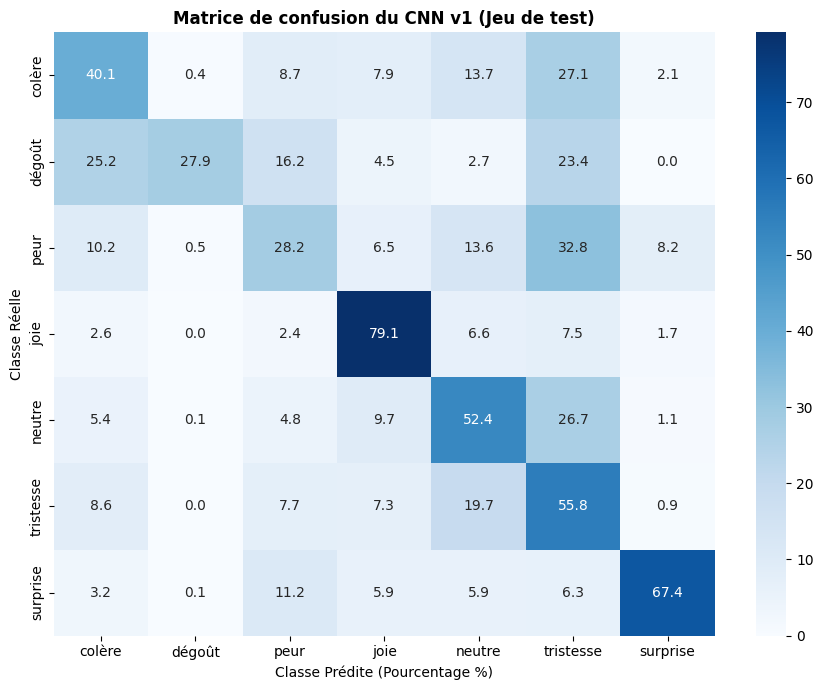

In [20]:
# Matrice de confusion normalisée par ligne : chaque case donne le pourcentage
# d'images d'une classe réelle (ligne) classées dans la classe en colonne
matrice_confusion(y_test, y_pred, "Matrice de confusion du CNN v1 (jeu de test)")

### Ce que montrent les résultats par classe

Le CNN v1 obtient **55,87 % d’accuracy sur le test**. La joie est de loin l’expression la mieux reconnue (rappel de 79,1 %, F1 de 0,783), suivie de la surprise (rappel de 67,4 %, F1 de 0,723). Ce sont aussi des expressions très marquées visuellement, ce qui n’est sans doute pas un hasard.

Le dégoût montre bien pourquoi le score global ne suffit pas : sa précision est de 73,8 %, mais son rappel n’est que de 27,9 %. Autrement dit, quand le modèle dit « dégoût », il a souvent raison, mais il passe à côté de la plupart des vrais visages dégoûtés. La peur a le même problème, avec un rappel de 28,2 %. La matrice de confusion permet de voir vers quelles expressions ces images sont envoyées à tort.

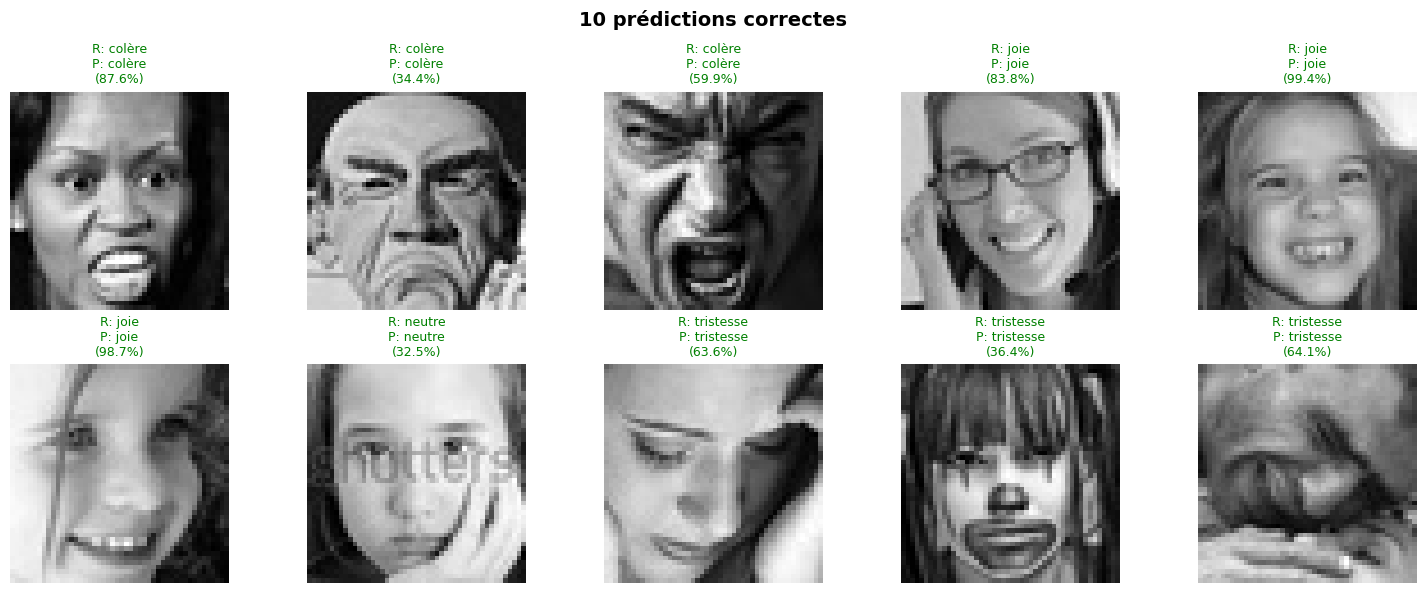

In [21]:
# 10 prédictions correctes, tirées au hasard (graine fixée)
rng = np.random.default_rng(SEED)
indices_correctes = sorted(rng.choice(np.where(y_pred == y_test)[0], size=10, replace=False))
afficher_predictions(cnn_v1, X_test_brut, y_test, indices_correctes,
                     "10 prédictions correctes")

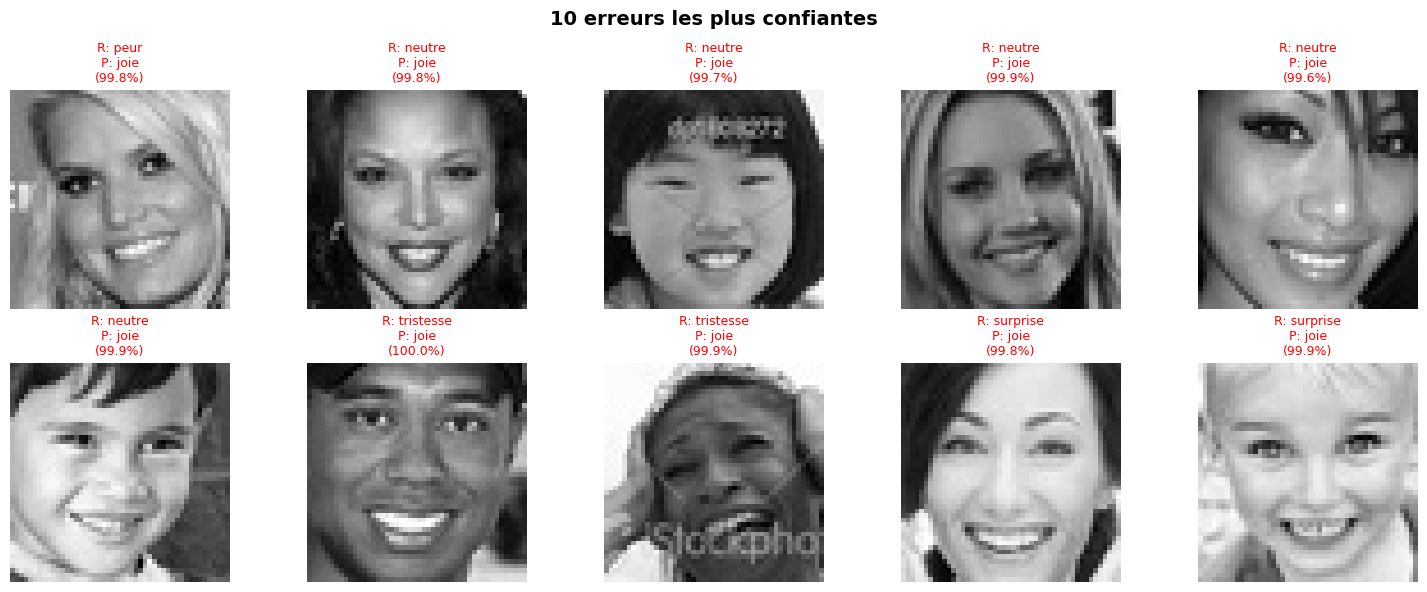

In [22]:
# Les 10 erreurs pour lesquelles le modèle était le plus sûr de lui
probas_test = cnn_v1.predict(X_test, verbose=0)
confiance = probas_test.max(axis=1)
indices_erreurs = np.where(y_pred != y_test)[0]
indices_erreurs = sorted(indices_erreurs[np.argsort(-confiance[indices_erreurs])][:10])
afficher_predictions(cnn_v1, X_test_brut, y_test, indices_erreurs,
                     "10 erreurs les plus confiantes")

### Analyse des erreurs

On affiche d’abord dix bonnes prédictions, puis les dix erreurs pour lesquelles le modèle était le plus confiant. Cette deuxième série rappelle une chose importante : une probabilité softmax élevée ne veut pas dire que la réponse est juste.

En regardant ces exemples, on retrouve des expressions qui se ressemblent et des images peu lisibles (visage de profil, main devant la bouche, image très sombre). Ça aide à comprendre certaines erreurs, mais dix images ne suffisent pas pour chiffrer leurs causes, ni pour affirmer que les erreurs d’annotation du dataset imposent un plafond précis aux performances.

Bilan de cette première comparaison : le CNN v1 monte à **57,59 % en validation**, contre 34,44 % pour le réseau dense, soit 23,15 points de mieux, et obtient 55,87 % sur le test. Les convolutions font clairement la différence. Reste à voir jusqu’où on peut pousser l’architecture.

## Partie 6 : Expérimentation et amélioration

On procède en deux temps :

1. **Une recherche aléatoire** sur 24 configurations différentes, entraînées 15 époques au maximum. On fait varier le nombre de blocs, les filtres, la taille des kernels, la couche dense, l’activation et le Dropout.
2. **Des expériences ciblées** à partir de la meilleure configuration, sur 25 époques au maximum : profondeur, nombre de filtres et taille des kernels, puis ajout progressif de régularisation.

La recherche tire des configurations au hasard, elle ne teste pas toute la grille. Si on passe `RUN_RECHERCHE` à `False`, les résultats sont relus depuis le CSV déjà sauvegardé, ce qui évite de tout réentraîner.

Une précision sur les chiffres : dans la pré-étude et les expériences, l’accuracy affichée est celle de l’époque où la perte de validation est la plus basse, alors que pour le CNN v1 on avait retenu la meilleure accuracy sur tout l’entraînement. Les deux ne sont donc pas calculées exactement de la même manière. Enfin, chaque essai n’a été lancé qu’une fois, avec une seule graine : les petits écarts sont à prendre avec prudence.

In [23]:
# Espace de recherche et tirage de 24 configurations distinctes (graine fixée)
ESPACE = {
    "nb_blocs":      [2, 3],
    "filtres":       [(32, 64), (64, 128), (32, 64, 128)],
    "taille_kernel": [3, 5],
    "nb_dense":      [128, 256],
    "activation":    ["relu", "elu"],
    "dropout":       [0.3, 0.5],
}
N_RECHERCHE = 24
RUN_RECHERCHE = True   # False = on relit le CSV au lieu de refaire toute la recherche

def normaliser_config(c):
    """Convertit les types numpy en types Python classiques (int, float, str, tuple)."""
    return dict(
        nb_blocs=int(c["nb_blocs"]),
        filtres=tuple(int(f) for f in c["filtres"]),
        taille_kernel=int(c["taille_kernel"]),
        nb_dense=int(c["nb_dense"]),
        activation=str(c["activation"]),
        dropout=float(c["dropout"]),
    )

rng_recherche = np.random.default_rng(SEED)
vues, configs_recherche = set(), []
while len(configs_recherche) < N_RECHERCHE:
    c = {k: v[rng_recherche.integers(len(v))] for k, v in ESPACE.items()}
    cle = tuple(sorted((k, str(v)) for k, v in c.items()))
    if cle not in vues:  # on évite de tirer deux fois la même configuration
        vues.add(cle)
        configs_recherche.append(normaliser_config(c))

print(f"{len(configs_recherche)} configurations tirées (graine {SEED})")

24 configurations tirées (seed 42)


In [24]:
# Pré-étude : chaque configuration est entraînée 15 époques au maximum.
# On réécrit le CSV après chaque configuration pour ne rien perdre si la session plante.
lignes_recherche = []

if RUN_RECHERCHE:
    for i, config in enumerate(configs_recherche):
        t0 = time.time()
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)
        modele = construire_cnn(**config)
        modele.compile(optimizer=keras.optimizers.Adam(1e-3),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        histo = modele.fit(X_train, y_train, batch_size=TAILLE_BATCH, epochs=15,
                           validation_data=(X_val, y_val),
                           callbacks=[keras.callbacks.EarlyStopping(
                               monitor="val_loss", patience=3,
                               restore_best_weights=True)],
                           verbose=0)
        h = histo.history
        j = int(np.argmin(h["val_loss"]))  # époque restaurée par EarlyStopping
        lignes_recherche.append({
            "nb_blocs": config["nb_blocs"],
            "filtres": "-".join(str(f) for f in config["filtres"]),
            "kernel": config["taille_kernel"],
            "dense": config["nb_dense"],
            "activation": config["activation"],
            "dropout": config["dropout"],
            "val_acc": round(float(h["val_accuracy"][j]), 4),
            "train_acc": round(float(h["accuracy"][j]), 4),
            "params": modele.count_params(),
            "s": round(time.time() - t0),
        })
        pd.DataFrame(lignes_recherche).to_csv(CHEMIN_RECHERCHE, index=False)
        print(f"config {i + 1}/{N_RECHERCHE} — val_acc = {h['val_accuracy'][j]:.3f}"
              f" — {round(time.time() - t0)} s")
        del modele, histo
else:
    print("RUN_RECHERCHE = False : recherche sautée, les résultats seront relus "
          "depuis le CSV dans la cellule suivante.")

config 1/24 — val_acc = 0.563 — 126 s
config 2/24 — val_acc = 0.538 — 91 s
config 3/24 — val_acc = 0.528 — 125 s
config 4/24 — val_acc = 0.251 — 201 s
config 5/24 — val_acc = 0.563 — 156 s
config 6/24 — val_acc = 0.518 — 71 s
config 7/24 — val_acc = 0.541 — 112 s
config 8/24 — val_acc = 0.563 — 156 s
config 9/24 — val_acc = 0.582 — 126 s
config 10/24 — val_acc = 0.547 — 105 s
config 11/24 — val_acc = 0.581 — 106 s
config 12/24 — val_acc = 0.577 — 134 s
config 13/24 — val_acc = 0.545 — 84 s
config 14/24 — val_acc = 0.510 — 127 s
config 15/24 — val_acc = 0.553 — 103 s
config 16/24 — val_acc = 0.520 — 68 s
config 17/24 — val_acc = 0.528 — 127 s
config 18/24 — val_acc = 0.513 — 64 s
config 19/24 — val_acc = 0.563 — 146 s
config 20/24 — val_acc = 0.524 — 106 s
config 21/24 — val_acc = 0.534 — 97 s
config 22/24 — val_acc = 0.492 — 105 s
config 23/24 — val_acc = 0.544 — 141 s
config 24/24 — val_acc = 0.551 — 72 s


In [25]:
# Résultats de la pré-étude, du meilleur au moins bon
if RUN_RECHERCHE:
    df_recherche = pd.DataFrame(lignes_recherche)
else:
    df_recherche = pd.read_csv(CHEMIN_RECHERCHE)
df_recherche = df_recherche.sort_values("val_acc", ascending=False).reset_index(drop=True)
display(df_recherche.head(10))

,nb_blocs,filtres,kernel,dense,activation,dropout,val_acc,train_acc,params,s
0,3,32-64-128,5,128,relu,0.3,0.5818,0.5996,1385703,126
1,3,32-64-128,3,256,relu,0.3,0.5809,0.6322,1468135,106
2,3,64-128,3,128,elu,0.3,0.5768,0.6054,665671,134
3,2,32-64-128,5,128,relu,0.5,0.5634,0.5656,1360871,126
4,3,64-128,3,256,elu,0.3,0.5634,0.6015,961607,156
5,3,64-128,3,128,relu,0.3,0.5631,0.5737,665671,146
6,3,64-128,3,256,relu,0.5,0.5626,0.5283,961607,156
7,3,32-64-128,3,128,elu,0.5,0.5528,0.5082,877287,103
8,3,32-64-128,3,128,elu,0.3,0.5508,0.5603,877287,72
9,2,32-64,5,128,elu,0.5,0.5472,0.5568,1360871,105


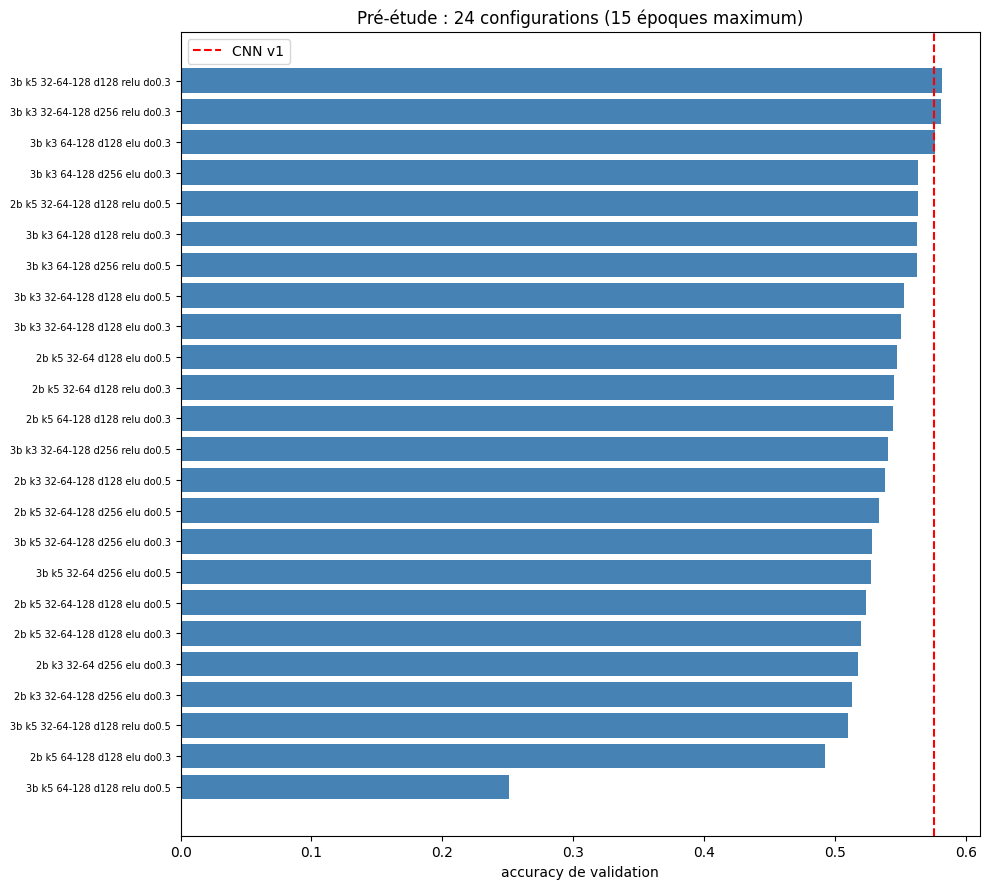

In [26]:
# Vue d'ensemble des 24 configurations, avec le CNN v1 comme repère (ligne rouge)
df_trie = df_recherche.sort_values("val_acc")
etiquettes = [
    f"{int(r.nb_blocs)}b k{int(r.kernel)} {r.filtres} d{int(r.dense)}"
    f" {r.activation} do{r.dropout}"
    for r in df_trie.itertuples()
]
plt.figure(figsize=(10, 9))
plt.barh(range(len(df_trie)), df_trie["val_acc"], color="steelblue")
plt.yticks(range(len(df_trie)), etiquettes, fontsize=7)
plt.xlabel("accuracy de validation")
plt.title("Pré-étude : 24 configurations (15 époques maximum)")
plt.axvline(meilleure_val_v1, color="red", linestyle="--", label="CNN v1")
plt.legend()
plt.tight_layout(); plt.show()

In [27]:
# On garde la meilleure configuration : elle sert de base aux expériences ciblées
meilleure = df_recherche.iloc[0]
MEILLEURE_CONFIG = dict(
    nb_blocs=int(meilleure["nb_blocs"]),
    filtres=tuple(int(x) for x in str(meilleure["filtres"]).split("-")),
    taille_kernel=int(meilleure["kernel"]),
    nb_dense=int(meilleure["dense"]),
    activation=str(meilleure["activation"]),
    dropout=float(meilleure["dropout"]),
)
print("MEILLEURE_CONFIG =", MEILLEURE_CONFIG)
print("val_acc =", meilleure["val_acc"])

MEILLEURE_CONFIG = {'nb_blocs': 3, 'filtres': (32, 64, 128), 'taille_kernel': 5, 'nb_dense': 128, 'activation': 'relu', 'dropout': 0.3}
val_acc = 0.5818


### Ce qu’on retient de la pré-étude

La meilleure configuration atteint **58,18 % en validation** : trois blocs, 32–64–128 filtres, des kernels **5×5**, une couche dense de 128 neurones, ReLU et un Dropout de 0,3, pour 1 385 703 paramètres. Juste derrière, à 58,09 %, on trouve une configuration avec des kernels 3×3 et 256 neurones denses : l’écart est minime.

Sur l’ensemble des 24 essais, les scores vont d’environ 25,13 % à 58,18 %, soit près de 33 points d’écart, ce qui montre que l’architecture compte beaucoup. Par contre, comme plusieurs paramètres changent en même temps d’un essai à l’autre, cette recherche repère de bonnes configurations sans dire quel réglage est responsable de quoi. C’est l’objet des expériences qui suivent.

### Expérience 1 : Impact de la profondeur

On compare un, deux, trois et quatre blocs, tous les autres réglages restant ceux de `MEILLEURE_CONFIG`. Petite subtilité : la fonction reboucle sur la liste des filtres, donc avec quatre blocs et `(32, 64, 128)`, le quatrième bloc n’a que 32 filtres. Il faut l’avoir en tête en lisant les résultats.

In [28]:
# Protocole commun aux trois expériences, puis expérience 1 (profondeur)
resultats_experiences = []

def protocole_entrainement(modele, epochs=25):
    """Compile et entraîne le modèle avec arrêt anticipé.
    Renvoie (val_acc à la meilleure époque, historique, indice de cette époque)."""
    modele.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    histo = modele.fit(X_train, y_train, batch_size=TAILLE_BATCH, epochs=epochs,
                       validation_data=(X_val, y_val),
                       callbacks=[keras.callbacks.EarlyStopping(
                           monitor="val_loss", patience=5, restore_best_weights=True)],
                       verbose=0)
    h = histo.history
    j = int(np.argmin(h["val_loss"]))
    return h["val_accuracy"][j], h, j

def lancer_experience(nom, **kwargs):
    """Entraîne MEILLEURE_CONFIG en ne changeant que le(s) réglage(s) passé(s) en argument."""
    config = {**MEILLEURE_CONFIG, **kwargs}
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    modele = construire_cnn(**config)
    val_acc, h, j = protocole_entrainement(modele)
    ligne = {"expérience": nom,
             "val_acc": round(float(val_acc), 4),
             "train_acc": round(float(h["accuracy"][j]), 4),
             "écart train-val": round(float(h["accuracy"][j] - val_acc), 4),
             "params": modele.count_params(),
             "époques": j + 1}
    resultats_experiences.append(ligne)
    print(f"{nom} — val_acc = {val_acc:.4f} ({j + 1} époques)")
    return ligne

for n in [1, 2, 3, 4]:
    lancer_experience(f"profondeur : {n} blocs", nb_blocs=n)
display(pd.DataFrame(resultats_experiences))

profondeur : 1 blocs — val_acc = 0.4896 (5 époques)
profondeur : 2 blocs — val_acc = 0.5389 (7 époques)
profondeur : 3 blocs — val_acc = 0.5670 (11 époques)
profondeur : 4 blocs — val_acc = 0.2513 (24 époques)


,expérience,val_acc,train_acc,écart train-val,params,époques
0,profondeur : 1 blocs,0.4896,0.5500,0.0604,2386791,5
1,profondeur : 2 blocs,0.5389,0.5670,0.0281,1360871,7
2,profondeur : 3 blocs,0.5670,0.5793,0.0123,1385703,11
3,profondeur : 4 blocs,0.2513,0.2513,-0.0000,960807,24


Les scores de validation sont de **48,96 % avec un bloc, 53,89 % avec deux, 56,70 % avec trois et 25,13 % avec quatre**. Trois blocs, c’est donc le meilleur compromis ici.

Le score à quatre blocs correspond presque exactement à la proportion de joie dans les données d’entraînement : le modèle n’a visiblement rien appris d’utile, même si on n’a pas vérifié qu’il répond « joie » à chaque fois. Avec quatre poolings, la résolution tombe de 48 à 24, 12, 6 puis 3 pixels, ce qui laisse très peu d’information spatiale. Ça peut jouer, mais ça n’explique probablement pas à lui seul un tel effondrement.

### Expérience 2 : Nombre de filtres et taille des kernels

On garde trois blocs et on compare d’abord plusieurs jeux de filtres, puis des kernels 3×3 et 5×5. Même remarque que tout à l’heure : avec seulement deux valeurs, la fonction reboucle, donc `(32, 64)` donne en réalité 32–64–32 sur les trois blocs.

In [29]:
# Expérience 2a : nombre de filtres par bloc (le reste = MEILLEURE_CONFIG)
for filtres in [(32, 64), (64, 128), (32, 64, 128), (64, 128, 256)]:
    lancer_experience(f"filtres : {'-'.join(str(f) for f in filtres)}", filtres=filtres)
display(pd.DataFrame(resultats_experiences[-4:]))

# Expérience 2b : taille des kernels (le reste = MEILLEURE_CONFIG)
for k in [3, 5]:
    lancer_experience(f"kernel : {k}x{k}", taille_kernel=k)
display(pd.DataFrame(resultats_experiences[-2:]))

filtres : 32-64 — val_acc = 0.5910 (20 époques)
filtres : 64-128 — val_acc = 0.5528 (24 époques)
filtres : 32-64-128 — val_acc = 0.5798 (15 époques)
filtres : 64-128-256 — val_acc = 0.2513 (24 époques)


,expérience,val_acc,train_acc,écart train-val,params,époques
0,filtres : 32-64,0.5910,0.6180,0.0271,405543,20
1,filtres : 64-128,0.5528,0.6127,0.0599,1322055,24
2,filtres : 32-64-128,0.5798,0.6109,0.0310,1385703,15
3,filtres : 64-128-256,0.2513,0.2513,-0.0000,4357575,24


kernel : 3x3 — val_acc = 0.5860 (12 époques)
kernel : 5x5 — val_acc = 0.5784 (16 époques)


,expérience,val_acc,train_acc,écart train-val,params,époques
0,kernel : 3x3,0.5860,0.5971,0.0112,877287,12
1,kernel : 5x5,0.5784,0.6059,0.0275,1385703,16


Côté filtres, c’est **32–64** (donc 32–64–32 en pratique) qui s’en sort le mieux avec **59,10 %**, et seulement 405 543 paramètres. Les versions 64–128 et 32–64–128 obtiennent 55,28 % et 57,98 %. Quant à 64–128–256, il retombe à 25,13 % : élargir le réseau n’a pas aidé, au contraire.

Pour les kernels, le 3×3 fait **58,60 %** contre 57,84 % pour le 5×5, avec moins de paramètres (877 287 contre 1 385 703). On le note honnêtement : malgré ces deux résultats, notre modèle final garde `MEILLEURE_CONFIG`, issue de la pré-étude, donc 32–64–128 filtres et des kernels 5×5. Les écarts restent faibles et n’ont été mesurés qu’une fois, mais une version plus légère aurait mérité d’être testée en final.

### Expérience 3 : Rôle de la régularisation

On garde l’architecture gagnante de la pré-étude et on compare quatre niveaux de régularisation :

- **R0** : ni Dropout, ni Batch Normalization, ni augmentation.
- **R1** : Dropout de 0,3.
- **R2** : Dropout + Batch Normalization après chaque convolution.
- **R3** : la même chose, plus de l’augmentation sur les images d’entraînement (retournements horizontaux, petites rotations, zooms et variations de contraste).

Comme on ajoute les techniques une par une, on mesure l’apport de chacune dans ce contexte précis, sans pour autant explorer toutes les combinaisons possibles.

In [30]:
# Expérience 3 : on ajoute la régularisation petit à petit (le reste = MEILLEURE_CONFIG)
lancer_experience("R0 : sans régularisation",
                  dropout=0.0, batchnorm=False, augmentation=False)
lancer_experience("R1 : dropout seul",
                  dropout=MEILLEURE_CONFIG["dropout"], batchnorm=False, augmentation=False)
lancer_experience("R2 : dropout + BatchNorm",
                  dropout=MEILLEURE_CONFIG["dropout"], batchnorm=True, augmentation=False)
lancer_experience("R3 : dropout + BatchNorm + augmentation",
                  dropout=MEILLEURE_CONFIG["dropout"], batchnorm=True, augmentation=True)

print("Récapitulatif de toutes les expériences :")
display(pd.DataFrame(resultats_experiences))

R0 : sans régularisation — val_acc = 0.4634 (5 époques)
R1 : dropout seul — val_acc = 0.5651 (14 époques)
R2 : dropout + BatchNorm — val_acc = 0.5921 (12 époques)
R3 : dropout + BatchNorm + augmentation — val_acc = 0.5952 (25 époques)
Tableau comparatif global des expériences :


,expérience,val_acc,train_acc,écart train-val,params,époques
0,profondeur : 1 blocs,0.4896,0.5500,0.0604,2386791,5
1,profondeur : 2 blocs,0.5389,0.5670,0.0281,1360871,7
2,profondeur : 3 blocs,0.5670,0.5793,0.0123,1385703,11
3,profondeur : 4 blocs,0.2513,0.2513,-0.0000,960807,24
4,filtres : 32-64,0.5910,0.6180,0.0271,405543,20
5,filtres : 64-128,0.5528,0.6127,0.0599,1322055,24
6,filtres : 32-64-128,0.5798,0.6109,0.0310,1385703,15
7,filtres : 64-128-256,0.2513,0.2513,-0.0000,4357575,24
8,kernel : 3x3,0.5860,0.5971,0.0112,877287,12
9,kernel : 5x5,0.5784,0.6059,0.0275,1385703,16


L’accuracy de validation passe de **46,34 % pour R0 à 56,51 % pour R1, 59,21 % pour R2 et 59,52 % pour R3**. C’est le Dropout qui apporte le plus gros gain (plus de 10 points), la Batch Normalization ajoute ensuite 2,70 points. L’augmentation, elle, n’apporte que 0,31 point dans cet essai : c’est trop peu pour conclure sans relancer l’expérience plusieurs fois.

Détail intéressant pour R3 : l’accuracy d’entraînement (58,22 %) est plus basse que celle de validation. Ce n’est pas une anomalie : à l’entraînement, les images sont déformées et le Dropout est actif, ce qui rend la tâche plus dure qu’en validation.

Pour le modèle final, on reprend l’architecture de la pré-étude avec toute la régularisation de R3, et on l’entraîne plus longtemps, en baissant le taux d’apprentissage quand la perte de validation stagne.

### Notre modèle final

Voici les réglages retenus :

- Trois blocs de deux convolutions, avec **32, 64 puis 128 filtres 5×5**.
- Une couche dense de **128 neurones**, ReLU, et un Dropout de **0,3**.
- Batch Normalization après chaque convolution et augmentation de données pendant l’entraînement.
- Adam, avec un taux d’apprentissage initial de 0,001.
- Arrêt anticipé sur la perte de validation (patience de 10), avec restauration des meilleurs poids.
- `ReduceLROnPlateau`, qui divise le taux d’apprentissage par deux après quatre époques sans progrès de la perte de validation, sans descendre sous 0,00001.

L’entraînement peut aller jusqu’à 60 époques. On n’a pas combiné tous les meilleurs réglages trouvés dans les expériences de profondeur et de filtres : on est resté sur `MEILLEURE_CONFIG`, en y ajoutant la régularisation.

Epoch 1/60
393/393 - 20s - 51ms/step - accuracy: 0.2464 - loss: 1.8710 - val_accuracy: 0.2608 - val_loss: 1.7772 - learning_rate: 0.0010
Epoch 2/60
393/393 - 15s - 38ms/step - accuracy: 0.3136 - loss: 1.7099 - val_accuracy: 0.3271 - val_loss: 1.6487 - learning_rate: 0.0010
Epoch 3/60
393/393 - 15s - 38ms/step - accuracy: 0.3633 - loss: 1.6117 - val_accuracy: 0.2750 - val_loss: 1.7077 - learning_rate: 0.0010
Epoch 4/60
393/393 - 15s - 38ms/step - accuracy: 0.3929 - loss: 1.5425 - val_accuracy: 0.3814 - val_loss: 1.5598 - learning_rate: 0.0010
Epoch 5/60
393/393 - 15s - 38ms/step - accuracy: 0.4102 - loss: 1.4848 - val_accuracy: 0.3959 - val_loss: 1.5032 - learning_rate: 0.0010
Epoch 6/60
393/393 - 15s - 38ms/step - accuracy: 0.4323 - loss: 1.4385 - val_accuracy: 0.4642 - val_loss: 1.3613 - learning_rate: 0.0010
Epoch 7/60
393/393 - 21s - 52ms/step - accuracy: 0.4503 - loss: 1.4040 - val_accuracy: 0.4338 - val_loss: 1.4177 - learning_rate: 0.0010
Epoch 8/60
393/393 - 15s - 38ms/step - ac

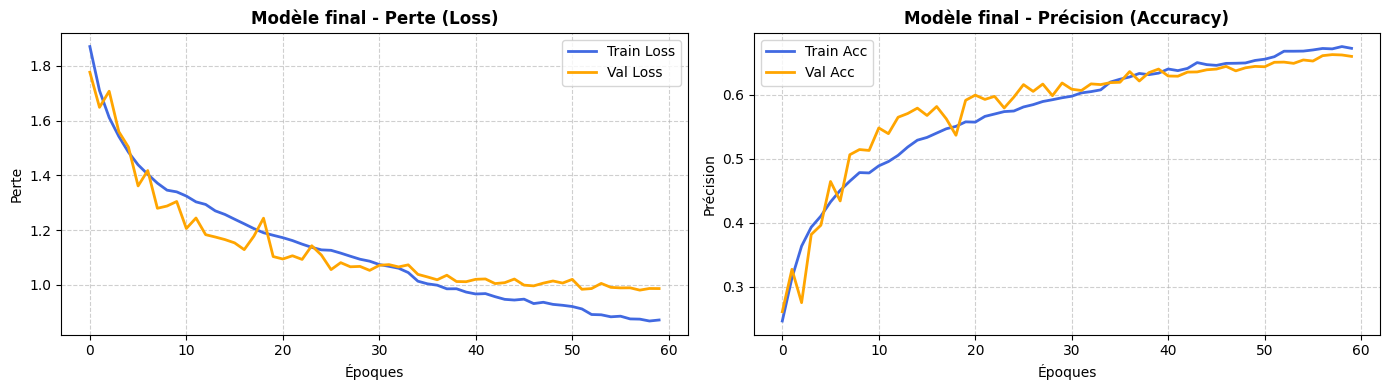

Modèle sauvegardé : /content/modele_final.keras


In [31]:
# Entraînement du modèle final : architecture gagnante + toute la régularisation
keras.utils.set_random_seed(SEED)
modele_final = construire_cnn(**MEILLEURE_CONFIG, batchnorm=True, augmentation=True)
modele_final.compile(optimizer=keras.optimizers.Adam(1e-3),
                     loss="sparse_categorical_crossentropy", metrics=["accuracy"])
rappels_finaux = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4,
                                      min_lr=1e-5, verbose=1),
]
histo_final = modele_final.fit(X_train, y_train, batch_size=TAILLE_BATCH, epochs=60,
                               validation_data=(X_val, y_val),
                               callbacks=rappels_finaux, verbose=2)
meilleure_val_final = max(histo_final.history["val_accuracy"])
plot_historique(histo_final, "Modèle final")
modele_final.save(CHEMIN_MODELE_FINAL)
print("Modèle sauvegardé :", CHEMIN_MODELE_FINAL)

Évaluation du modèle sur le jeu de test...


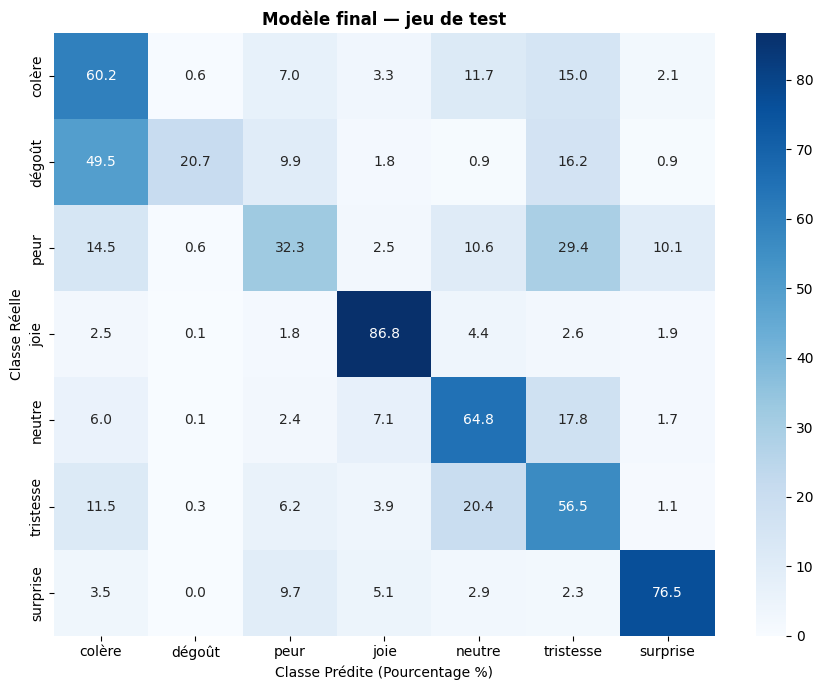

In [32]:
# Évaluation du modèle final sur le jeu de test
y_pred_final = rapport_evaluation(modele_final, X_test, y_test, "test")
acc_test_final = accuracy_score(y_test, y_pred_final)
matrice_confusion(y_test, y_pred_final, "Modèle final — jeu de test")

In [33]:
# Tableau récapitulatif des modèles (on y ajoutera MobileNetV2 en partie 7)
df_recap = pd.DataFrame([
    {"modèle": "Baseline dense", "params": baseline.count_params(),
     "val_acc": round(float(meilleure_val_baseline), 4), "test_acc": "—"},
    {"modèle": "CNN v1", "params": cnn_v1.count_params(),
     "val_acc": round(float(meilleure_val_v1), 4), "test_acc": round(float(acc_test_v1), 4)},
    {"modèle": "Modèle final", "params": modele_final.count_params(),
     "val_acc": round(float(meilleure_val_final), 4),
     "test_acc": round(float(acc_test_final), 4)},
])
display(df_recap)

,modèle,params,val_acc,test_acc
0,Baseline dense,591879,0.3444,—
1,CNN v1,1245671,0.5759,0.5587
2,Modèle final,1387495,0.6623,0.6421


## Partie 7 : Transfer learning avec MobileNetV2

On essaie maintenant de partir d’un modèle déjà entraîné : MobileNetV2, avec ses poids appris sur ImageNet. Pour qu’il accepte nos images, on les agrandit en 96×96, on recopie le canal gris trois fois pour simuler du RGB, et on passe les valeurs de `[0, 1]` à `[-1, 1]` avec `2x - 1`, comme MobileNetV2 l’attend. Évidemment, agrandir l’image n’ajoute aucun détail : on adapte juste le format.

L’entraînement se fait en deux phases. D’abord, le backbone est gelé et on entraîne seulement une petite tête : GlobalAveragePooling, 128 neurones ReLU, Dropout de 0,4 et sortie softmax. Ensuite, on dégèle uniquement les vingt dernières couches du backbone pour un fine-tuning avec un taux d’apprentissage très faible (0,00001). Le backbone est appelé avec `training=False`, pour que ses couches de Batch Normalization restent en mode inférence et ne soient pas perturbées par nos données.

In [3]:
# Préparation des données pour MobileNetV2 : 48x48x1 dans [0, 1] -> 96x96x3 dans [-1, 1]
# On traite les images par lots de 5000 pour ne pas saturer la mémoire
def preparer_pour_transfert(X, taille_lot=5000):
    lots = []
    for debut in range(0, len(X), taille_lot):
        lot = tf.image.resize(X[debut:debut + taille_lot], (96, 96))
        lot = tf.image.grayscale_to_rgb(lot)
        lots.append(lot.numpy())
    return np.concatenate(lots).astype("float32") * 2.0 - 1.0

X_tl_train = preparer_pour_transfert(X_train)
X_tl_val = preparer_pour_transfert(X_val)
X_tl_test = preparer_pour_transfert(X_test)
print(X_tl_train.shape, X_tl_val.shape, X_tl_test.shape)
print("min/max :", X_tl_train.min(), X_tl_train.max())

(25120, 96, 96, 3) (3589, 96, 96, 3) (7178, 96, 96, 3)
min/max : -1.0 1.0


In [6]:
# Phase 1 : backbone gelé, on n'entraîne que la tête de classification
keras.utils.set_random_seed(SEED)
base = keras.applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False,
                                      weights="imagenet")
base.trainable = False

entrees = keras.Input(shape=(96, 96, 3))
x = base(entrees, training=False)  # la BatchNorm du backbone reste en mode inférence
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)
sorties = layers.Dense(NB_CLASSES, activation="softmax")(x)
modele_tl = keras.Model(entrees, sorties, name="mobilenetv2_transfert")

modele_tl.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

histo_tl = modele_tl.fit(X_tl_train, y_train, batch_size=128, epochs=20,
                         validation_data=(X_tl_val, y_val),
                         callbacks=[keras.callbacks.EarlyStopping(
                             monitor="val_loss", patience=4,
                             restore_best_weights=True)],
                         verbose=2)
meilleure_val_tl = max(histo_tl.history["val_accuracy"])

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20
197/197 - 38s - 191ms/step - accuracy: 0.3672 - loss: 1.6376 - val_accuracy: 0.4492 - val_loss: 1.4726
Epoch 2/20
197/197 - 6s - 30ms/step - accuracy: 0.4371 - loss: 1.4740 - val_accuracy: 0.4656 - val_loss: 1.4293
Epoch 3/20
197/197 - 11s - 57ms/step - accuracy: 0.4570 - loss: 1.4178 - val_accuracy: 0.4709 - val_loss: 1.3920
Epoch 4/20
197/197 - 6s - 31ms/step - accuracy: 0.4717 - loss: 1.3779 - val_accuracy: 0.4681 - val_loss: 1.3844
Epoch 5/20
197/197 - 10s - 52ms/step - accuracy: 0.4859 - loss: 1.3457 - val_accuracy: 0.4820 - val_loss: 1.3665
Epoch 6/20
197/197 - 6s - 30ms/step - accuracy: 0.4919 - loss: 1.3228 - val_accuracy: 0.4709 - val_loss: 1.3584
Epoch 7/20
197/197 - 7s - 33ms/step - accuracy: 0.5082 - loss: 1.2897 - val_accuracy: 0.4734 - val_loss: 1.3583
Epoch 8/20
197/197 - 6s - 29ms/step - accuracy: 0.5190 - loss: 1.2714 - val_accuracy: 0.4792 - val_loss: 1.3520
Epoch 9/20
197/197 - 6s - 31ms/step - accuracy: 0.5

Epoch 1/10
197/197 - 34s - 170ms/step - accuracy: 0.4068 - loss: 1.6490 - val_accuracy: 0.4762 - val_loss: 1.4189
Epoch 2/10
197/197 - 7s - 35ms/step - accuracy: 0.4500 - loss: 1.4640 - val_accuracy: 0.4717 - val_loss: 1.4259
Epoch 3/10
197/197 - 7s - 36ms/step - accuracy: 0.4734 - loss: 1.3831 - val_accuracy: 0.4717 - val_loss: 1.4125
Epoch 4/10
197/197 - 7s - 36ms/step - accuracy: 0.4967 - loss: 1.3099 - val_accuracy: 0.4809 - val_loss: 1.4093
Epoch 5/10
197/197 - 7s - 35ms/step - accuracy: 0.5143 - loss: 1.2556 - val_accuracy: 0.4829 - val_loss: 1.4019
Epoch 6/10
197/197 - 7s - 36ms/step - accuracy: 0.5349 - loss: 1.2093 - val_accuracy: 0.4845 - val_loss: 1.3940
Epoch 7/10
197/197 - 7s - 35ms/step - accuracy: 0.5512 - loss: 1.1666 - val_accuracy: 0.4854 - val_loss: 1.3879
Epoch 8/10
197/197 - 7s - 36ms/step - accuracy: 0.5703 - loss: 1.1200 - val_accuracy: 0.4890 - val_loss: 1.3824
Epoch 9/10
197/197 - 7s - 35ms/step - accuracy: 0.5778 - loss: 1.0892 - val_accuracy: 0.4882 - val_los

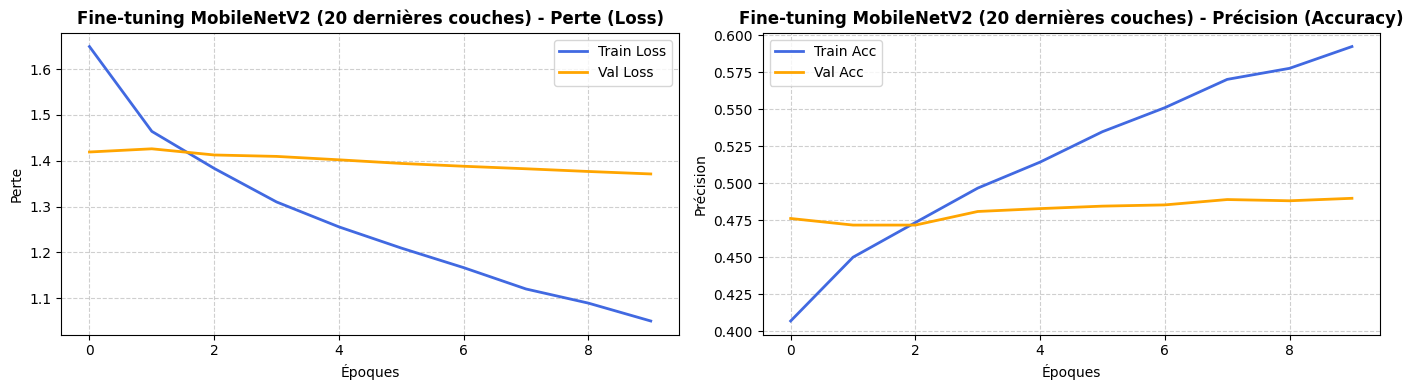

In [9]:
# Phase 2 : fine-tuning léger, on ne dégèle que les 20 dernières couches du backbone
base.trainable = True
for couche in base.layers[:-20]:
    couche.trainable = False

modele_tl.compile(optimizer=keras.optimizers.Adam(1e-5),  # taux très faible pour ne pas tout casser
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
histo_ft = modele_tl.fit(X_tl_train, y_train, batch_size=128, epochs=10,
                         validation_data=(X_tl_val, y_val),
                         callbacks=[keras.callbacks.EarlyStopping(
                             monitor="val_loss", patience=3,
                             restore_best_weights=True)],
                         verbose=2)
meilleure_val_tl = max(meilleure_val_tl, max(histo_ft.history["val_accuracy"]))
plot_historique(histo_ft, "Fine-tuning MobileNetV2 (20 dernières couches)")

In [ ]:
# Évaluation de MobileNetV2 sur le test, puis ajout au tableau récapitulatif
y_pred_tl = rapport_evaluation(modele_tl, X_tl_test, y_test, "test")
acc_test_tl = accuracy_score(y_test, y_pred_tl)

df_recap.loc[len(df_recap)] = {"modèle": "Transfert MobileNetV2",
                               "params": modele_tl.count_params(),
                               "val_acc": round(float(meilleure_val_tl), 4),
                               "test_acc": round(float(acc_test_tl), 4)}
display(df_recap)

# On libère la mémoire : les versions 96x96x3 occupent environ 3 Go de RAM
del X_tl_train, X_tl_val, X_tl_test

### Bilan du transfer learning

La première phase monte au mieux à **49,15 % en validation**, et le fine-tuning à **48,98 %** : dégeler les dernières couches n’a donc rien apporté. À noter, `meilleure_val_tl` garde le maximum des deux phases, ce qui ne correspond pas forcément aux poids évalués ensuite sur le test.

Lors de notre exécution, la session Colab a été réinitialisée avant l’évaluation sur le test, si bien qu’on n’a pas de score de test enregistré pour MobileNetV2 (la cellule a depuis été corrigée et fonctionne si on relance le notebook de bout en bout). En validation en tout cas, MobileNetV2 reste nettement derrière notre CNN final, qui monte jusqu’à 66,23 %. Une explication possible : les images d’ImageNet (objets, animaux, scènes en couleur) sont très différentes des petits visages en niveaux de gris de FER-2013. Mais nos essais ne permettent pas de le démontrer.

## Partie 8 : Détecter et classer plusieurs visages

Jusqu’ici, le modèle recevait des visages déjà recadrés. Sur une vraie photo, il faut d’abord trouver où sont les visages. On essaie de charger YOLOv8-face et, si ça échoue, on utilise la cascade de Haar d’OpenCV. Lors de notre exécution, c’est la cascade de Haar qui a été utilisée.

Chaque visage détecté est découpé avec une marge de 15 %, passé en niveaux de gris, redimensionné en 48×48 et normalisé, exactement comme pendant l’entraînement, avant d’être envoyé au CNN final. On teste d’abord la chaîne sur trois images composées de quatre visages du jeu de test (la session ayant redémarré au moment de cette démonstration, ses résultats n’ont pas été enregistrés), puis sur une vraie photo téléversée : le modèle y prédit `happy` avec une probabilité arrondie à 1,00.

In [ ]:
# Garde-fou : si la session a redémarré, on recharge le modèle final sauvegardé
# au lieu de devoir tout réentraîner
if "modele_final" not in globals():
    if os.path.exists(CHEMIN_MODELE_FINAL):
        modele_final = keras.models.load_model(CHEMIN_MODELE_FINAL)
        print("Modèle final rechargé depuis", CHEMIN_MODELE_FINAL)
    else:
        raise RuntimeError("Modèle final introuvable : relancez la partie 6 pour l'entraîner.")
else:
    print("Modèle final déjà en mémoire.")

In [16]:
# Chargement du détecteur de visages : on tente YOLOv8-face, sinon on se rabat sur la cascade de Haar
DETECTEUR = None
NOM_DETECTEUR = ""
try:
    from ultralytics import YOLO
    try:
        yolo_visage = YOLO("https://huggingface.co/arnabd13/YOLOv8n-face/"
                           "resolve/main/yolov8n-face.pt")
        DETECTEUR, NOM_DETECTEUR = yolo_visage, "YOLOv8n-face"
    except Exception as e:
        print("YOLO visage indisponible :", e)
except Exception as e:
    print("ultralytics indisponible :", e)

if DETECTEUR is None:
    import cv2
    cascade = cv2.CascadeClassifier(cv2.data.haarcascades +
                                    "haarcascade_frontalface_default.xml")
    DETECTEUR, NOM_DETECTEUR = cascade, "Haar Cascade (OpenCV)"

print("Détecteur utilisé :", NOM_DETECTEUR)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO visage indisponible : ❌  Download failure for https://huggingface.co/arnabd13/YOLOv8n-face/resolve/main/yolov8n-face.pt. 401 Client Error: Unauthorized for url: https://huggingface.co/arnabd13/YOLOv8n-face/resolve/main/yolov8n-face.pt
Détecteur utilisé : Haar Cascade (OpenCV)


In [21]:
# Même interface quel que soit le détecteur : une liste de boîtes (x1, y1, x2, y2, score)
def detecter_visages(image_rgb):
    boites = []
    if NOM_DETECTEUR.startswith("YOLO"):
        import cv2
        # ultralytics attend des images BGR quand on lui passe un tableau numpy
        image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
        resultats = DETECTEUR.predict(image_bgr, verbose=False, conf=0.35)
        for b in resultats[0].boxes:
            x1, y1, x2, y2 = [int(v) for v in b.xyxy[0].tolist()]
            boites.append((x1, y1, x2, y2, float(b.conf[0])))
    else:
        import cv2
        gris = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
        detections = DETECTEUR.detectMultiScale(gris, scaleFactor=1.1, minNeighbors=5,
                                                minSize=(30, 30))
        for (x, y, l, h) in detections:
            boites.append((int(x), int(y), int(x + l), int(y + h), None))
    return boites

In [22]:
# Chaîne complète sur une image : détection -> découpe du visage -> même prétraitement
# qu'à l'entraînement (48x48, gris, /255) -> CNN -> annotation
import cv2

NOMS_SANS_ACCENT = {"angry": "colere", "disgust": "degout", "fear": "peur",
                    "happy": "joie", "neutral": "neutre", "sad": "tristesse",
                    "surprise": "surprise"}  # cv2.putText ne gère pas les accents

def analyser_image(image_rgb, afficher=True):
    """Renvoie (image annotée BGR, liste des prédictions)."""
    image_annotee = cv2.cvtColor(image_rgb.copy(), cv2.COLOR_RGB2BGR)
    predictions = []
    for (x1, y1, x2, y2, score) in detecter_visages(image_rgb):
        # On élargit la boîte de 15 % pour cadrer le visage comme dans FER-2013
        mx = int((x2 - x1) * 0.15)
        my = int((y2 - y1) * 0.15)
        xa, ya = max(0, x1 - mx), max(0, y1 - my)
        xb, yb = min(image_rgb.shape[1], x2 + mx), min(image_rgb.shape[0], y2 + my)
        visage = image_rgb[ya:yb, xa:xb]
        if visage.size == 0:
            continue
        # Exactement le même prétraitement qu'à l'entraînement : 48x48, gris, /255
        gris = Image.fromarray(visage).convert("L").resize((48, 48))
        entree = (np.array(gris, dtype=np.float32) / 255.0).reshape(1, 48, 48, 1)
        probas = modele_final.predict(entree, verbose=0)[0]
        c = int(np.argmax(probas))
        p = float(probas[c])
        predictions.append({"boite": (xa, ya, xb, yb), "classe": CLASSES[c], "prob": p})
        texte = f"{NOMS_SANS_ACCENT[CLASSES[c]]} {p:.2f}"
        cv2.rectangle(image_annotee, (xa, ya), (xb, yb), (0, 200, 0), 2)
        cv2.putText(image_annotee, texte, (xa, max(15, ya - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 200, 0), 2)
    if afficher:
        plt.figure(figsize=(7, 7))
        plt.imshow(cv2.cvtColor(image_annotee, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.title(f"Détection + reconnaissance — {NOM_DETECTEUR}")
        plt.show()
    return image_annotee, predictions

In [23]:
# Fabrication d'images de groupe : on colle des visages du jeu de test, agrandis,
# sur un fond gris. Pratique pour tester sans avoir besoin de photo externe.
def creer_image_groupe(n_visages=4, taille=(320, 320), graine=None):
    """Renvoie (image RGB, étiquettes, positions des visages collés)."""
    rng_local = np.random.default_rng(graine if graine is not None else SEED)
    largeur, hauteur = taille
    image = Image.fromarray(np.full((hauteur, largeur, 3), 90, dtype=np.uint8))
    etiquettes, positions = [], []
    colonnes = int(np.ceil(np.sqrt(n_visages)))
    lignes = int(np.ceil(n_visages / colonnes))
    cw, ch = largeur // colonnes, hauteur // lignes
    for k in range(n_visages):
        idx = int(rng_local.integers(len(X_test_brut)))
        etiquettes.append(int(y_test[idx]))
        visage = np.stack([X_test_brut[idx]] * 3, axis=2)
        visage = np.array(Image.fromarray(visage).resize((96, 96)))
        x = (k % colonnes) * cw + int(rng_local.integers(max(1, cw - 96)))
        y = (k // colonnes) * ch + int(rng_local.integers(max(1, ch - 96)))
        image.paste(Image.fromarray(visage), (x, y))
        positions.append((x, y))
    return np.array(image), etiquettes, positions

In [ ]:
# Démonstration sur 3 images de groupe, avec un petit bilan chiffré
# (on associe chaque visage collé à la boîte détectée la plus proche, au sens de l'IoU)
def iou(a, b):
    """Intersection over Union de deux boîtes (x1, y1, x2, y2)."""
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    aire_a = (a[2] - a[0]) * (a[3] - a[1])
    aire_b = (b[2] - b[0]) * (b[3] - b[1])
    return inter / (aire_a + aire_b - inter + 1e-9)

n_detectes, n_visages, n_correctes = 0, 0, 0
for k in range(3):
    image_groupe, vraies, positions = creer_image_groupe(n_visages=4, graine=SEED + k)
    _, preds = analyser_image(image_groupe, afficher=True)
    boites_vraies = [(x, y, x + 96, y + 96) for (x, y) in positions]
    n_visages += len(boites_vraies)
    for c, boite_vraie in enumerate(boites_vraies):
        if not preds:
            break
        j = max(range(len(preds)), key=lambda i: iou(preds[i]["boite"], boite_vraie))
        if iou(preds[j]["boite"], boite_vraie) > 0.2:
            n_detectes += 1
            if preds[j]["classe"] == CLASSES[vraies[c]]:
                n_correctes += 1

print(f"Détection : {n_detectes}/{n_visages} visages trouvés "
      f"({100 * n_detectes / n_visages:.0f} %)")
if n_detectes:
    print(f"Expressions correctes (visages détectés) : {n_correctes}/{n_detectes} "
          f"({100 * n_correctes / n_detectes:.0f} %)")

Saving GettyImages-488226322.webp to GettyImages-488226322.webp


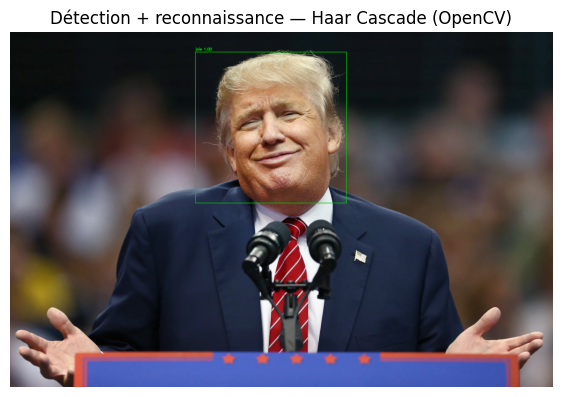

happy — probabilité 1.00


In [30]:
# Test sur une vraie photo (sur Colab, une fenêtre de téléversement s'ouvre).
# Passez EXECUTER_UPLOAD à False pour sauter cette étape.
EXECUTER_UPLOAD = True

if EXECUTER_UPLOAD:
    try:
        from google.colab import files
    except ImportError:
        files = None
        print("Cette cellule ne fonctionne que sur Google Colab.")
    if files is not None:
        envoye = files.upload()
        for nom_fichier in envoye.keys():
            image_televersee = np.array(Image.open(nom_fichier).convert("RGB"))
            _, predictions_photo = analyser_image(image_televersee, afficher=True)
            if not predictions_photo:
                print("Aucun visage détecté sur cette photo.")
            for p in predictions_photo:
                print(f"{p['classe']} — probabilité {p['prob']:.2f}")
else:
    print("EXECUTER_UPLOAD = False : passez-le à True pour tester sur votre photo.")

## Partie 9 : Passage à la vidéo

Pour la vidéo, on applique simplement la même chaîne à chaque image : détection, découpe du visage, prétraitement, classification et annotation. Les images annotées sont réécrites dans une nouvelle vidéo, avec la même résolution et la même fréquence que l’originale. On ne réduit pas la résolution et on ne fait aucun lissage dans le temps : chaque image est traitée indépendamment.

Notre vidéo de test synthétique fait **60 images à 12 images/s**, soit cinq secondes. Son traitement a pris **19,3 secondes** (et 19,7 secondes lors d’une seconde exécution), soit environ 3,1 images par seconde. La vidéo qu’on a téléversée compte **930 images**, traitées en **317,9 secondes**, soit 2,9 images/s. Le pipeline fonctionne, mais on est loin du temps réel : il faudrait aller environ quatre fois plus vite pour suivre une vidéo à 12 images/s.

Les vidéos annotées sont enregistrées dans `/content/video_annotee.mp4` (test synthétique) et `/content/testvideo.mp4` (vidéo téléversée). On n’a pas calculé de score de reconnaissance sur les vidéos.

In [31]:
# Création d'une vidéo de test : des images de groupe dont les visages
# changent toutes les 15 images
import cv2

def creer_video_test(nb_frames=60, fps=12, taille=(480, 360),
                     chemin="/content/video_test.mp4"):
    """Écrit la vidéo de test et renvoie les vraies étiquettes de chaque image."""
    redacteur = cv2.VideoWriter(chemin, cv2.VideoWriter_fourcc(*"mp4v"), fps, taille)
    etiquettes_par_frame = []
    for f in range(nb_frames):
        scene = f // 15  # on change de visages toutes les 15 images
        image, vraies, _ = creer_image_groupe(n_visages=4, taille=taille,
                                              graine=SEED + 100 + scene)
        redacteur.write(cv2.cvtColor(image, cv2.COLOR_RGB2BGR))
        etiquettes_par_frame.append(vraies)
    redacteur.release()
    print(f"Vidéo de test créée : {chemin} ({nb_frames} frames, {fps} ips)")
    return etiquettes_par_frame

etiquettes_video = creer_video_test(nb_frames=60, fps=12, taille=(480, 360))

Vidéo de test créée : /content/video_test.mp4 (60 frames, 12 ips)


In [32]:
# Analyse d'une vidéo complète, image par image, et écriture de la vidéo annotée
def analyser_video(chemin_entree, chemin_sortie):
    capture = cv2.VideoCapture(chemin_entree)
    if not capture.isOpened():
        raise FileNotFoundError(f"Impossible d'ouvrir la vidéo : {chemin_entree}")
    largeur = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    hauteur = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = capture.get(cv2.CAP_PROP_FPS) or 25  # certaines vidéos ne renseignent pas leur fréquence
    redacteur = cv2.VideoWriter(chemin_sortie, cv2.VideoWriter_fourcc(*"mp4v"),
                                fps, (largeur, hauteur))
    n, t0 = 0, time.time()
    while True:
        ok, frame_bgr = capture.read()
        if not ok:
            break
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        image_annotee, _ = analyser_image(frame_rgb, afficher=False)
        redacteur.write(image_annotee)
        n += 1
    capture.release()
    redacteur.release()
    duree = time.time() - t0
    print(f"{n} frames traitées en {duree:.1f} s — soit {n / max(duree, 1e-9):.1f} frames/s")
    print(f"Vidéo annotée : {chemin_sortie}")

60 frames traitées en 19.3 s — soit 3.1 frames/s
Vidéo annotée : /content/video_annotee.mp4


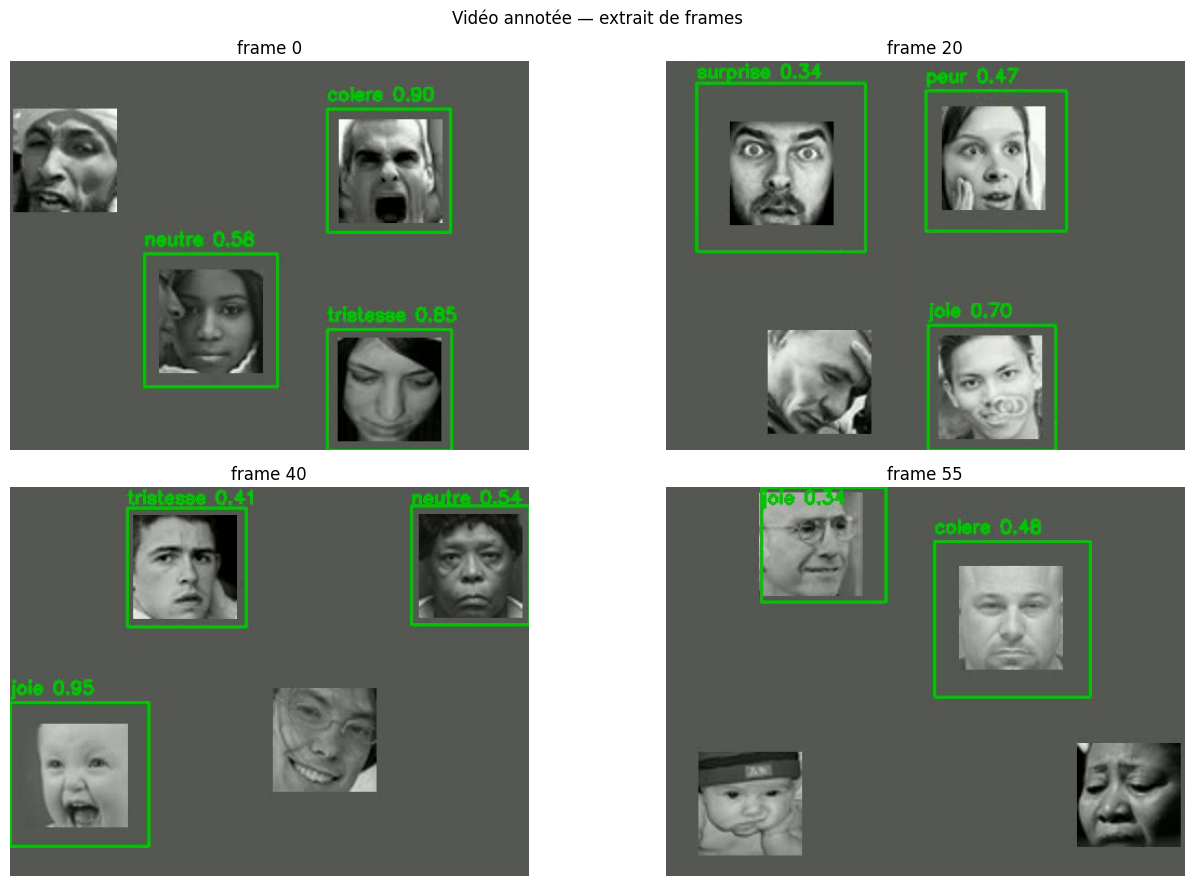

Vidéo annotée disponible : /content/video_annotee.mp4


In [34]:
# On lance le pipeline sur la vidéo de test, puis on affiche quelques images annotées
analyser_video("/content/video_test.mp4", "/content/video_annotee.mp4")

capture = cv2.VideoCapture("/content/video_annotee.mp4")
frames, index_vises, i = [], [0, 20, 40, 55], 0
while True:
    ok, frame = capture.read()
    if not ok:
        break
    if i in index_vises:
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    i += 1
capture.release()

plt.figure(figsize=(14, 9))
for k, frame in enumerate(frames):
    plt.subplot(2, 2, k + 1)
    plt.imshow(frame)
    plt.axis("off")
    plt.title(f"frame {index_vises[k]}")
plt.suptitle("Vidéo annotée — quelques frames")
plt.tight_layout(); plt.show()

print("Vidéo annotée disponible : /content/video_annotee.mp4")

In [ ]:
# Test sur votre propre vidéo (Colab uniquement). Passez EXECUTER_UPLOAD_VIDEO à False pour sauter.
EXECUTER_UPLOAD_VIDEO = True

if EXECUTER_UPLOAD_VIDEO:
    try:
        from google.colab import files
        envoye = files.upload()  # choisir un fichier .mp4
        if envoye:
            analyser_video(list(envoye.keys())[0], "/content/testvideo.mp4")
            print("Vidéo annotée téléchargeable via le panneau Fichiers : /content/testvideo.mp4")
    except ImportError:
        print("Cette cellule ne fonctionne que sur Google Colab.")
else:
    print("EXECUTER_UPLOAD_VIDEO = False : passez-le à True pour tester votre vidéo.")

Saving Pour Donald Trump, le prix Nobel de la paix se _discréditerait_ s'il ne le recevait pas.mp4 to Pour Donald Trump, le prix Nobel de la paix se _discréditerait_ s'il ne le recevait pas.mp4
930 frames traitées en 317.9 s — soit 2.9 frames/s
Vidéo annotée : /content/testvideo.mp4


## Conclusion

Au fil du projet, les résultats progressent nettement. Le réseau dense plafonne à **34,44 % en validation**, le CNN v1 monte à **57,59 % en validation et 55,87 % sur le test**, et le CNN final (1 387 495 paramètres) atteint **66,23 % en validation et 64,21 % sur le test**, soit 8,34 points de mieux que le CNN v1 sur le test. Pour donner un ordre d’idée, la performance humaine sur FER-2013 est souvent estimée autour de 65 % : on est donc dans des valeurs cohérentes pour ce dataset.

Pour être précis, les scores de validation cités sont les meilleurs atteints pendant l’entraînement, alors que les scores de test sont calculés avec les poids restaurés (ceux de la plus faible perte de validation). MobileNetV2 n’a pas dépassé 49,15 % en validation, et on n’a pas de score de test enregistré pour lui, ce qui limite la comparaison.

On a aussi branché le CNN final derrière un détecteur de visages pour l’appliquer à une photo et à des vidéos. Le chargement de YOLO ayant échoué, c’est la cascade de Haar d’OpenCV qui a fait le travail. La chaîne complète fonctionne sur nos exemples, mais ça ne prouve pas qu’elle est fiable sur un vrai ensemble de photos. Côté vitesse, on tourne à environ trois images par seconde.

### Limites

- Les classes sont très déséquilibrées : pour le CNN v1, le rappel n’est que de 27,9 % pour le dégoût et de 28,2 % pour la peur.
- Chaque essai n’a été lancé qu’avec une seule graine, donc les petits écarts entre configurations restent à confirmer.
- Le jeu de test a été consulté pour plusieurs modèles au cours du projet, et pas une seule fois à la toute fin.
- On n’a pas d’évaluation chiffrée sur les photos et les vidéos, et une erreur de détection peut fausser la classification qui suit.
- Une forte probabilité softmax peut accompagner une erreur, comme le montrent les erreurs les plus confiantes.

### Pour aller plus loin

Plusieurs pistes nous paraissent intéressantes : pondérer les classes ou sur-échantillonner les expressions rares, répéter les expériences avec plusieurs graines, et tester en final les configurations plus légères repérées dans les expériences (32–64–32 filtres, kernels 3×3). Un modèle pré-entraîné spécifiquement sur des visages serait sans doute plus adapté que MobileNetV2/ImageNet. Pour la vidéo, un lissage des prédictions d’une image à l’autre et une optimisation du traitement amélioreraient à la fois la stabilité des annotations et la vitesse.

Ce projet nous a surtout permis de suivre toute la chaîne, de la préparation des données jusqu’à une application concrète. Et il nous a appris à nous méfier d’un score global : avant de dire qu’un modèle est meilleur, il faut regarder les résultats par classe et la manière dont l’évaluation a été faite.